# Part 1 (ii): Time series: House Property Sales
**CMPE 255: EDA, data preparation and AutoML on a time series**

| | |
|---|---|
| **Dataset** | [House Property Sales Time Series (Kaggle)](https://www.kaggle.com/datasets/htagholdings/property-sales): `raw_sales.csv` has 29,580 individual residential sales (date, postcode, price, house/unit, bedrooms) in the Canberra/ACT region, 2007 to 2019. `ma_lga_12345.csv` is the publisher's quarterly moving-average median price by property type and bedrooms. |
| **Why this dataset** | Raw transactions arrive at **irregular dates** and must be turned into a regular series. Early years are sparse, some weeks have no sales, prices range from $56k to $8M, and some records are inconsistent (e.g. houses with 0 bedrooms). So cleaning, imputation and anomaly handling are all genuinely needed. |
| **Forecasting task** | Predict next week's **median house sale price** from information available up to the previous week |
| **AutoML** | AutoViML (regression) + AutoViz |

### Pipeline
```
Load → Overview → Data-quality audit → Transaction-level EDA → Auto-EDA (AutoViz)
     → Transaction cleaning (types, impossible values, price anomalies)
     → Aggregate to a weekly series → Time-ordered train/test split
     → Imputation of missing weeks (method chosen empirically, train/test imputed separately)
     → Time-series EDA (trend, seasonality, stationarity, autocorrelation)
     → Series-level anomaly removal (train only) → Clustering of postcodes by price trajectory
     → Lag/rolling/calendar feature engineering → Feature selection
     → AutoViML models + naive baselines → Evaluation → Conclusions
```
**Leakage rules for time series:** the split is **chronological** (never random). Every feature at week *t* uses only data up to week *t−1*. Anything learned from data (imputation choice, anomaly thresholds, clusters, feature selection) is learned on the training period only.

### How this notebook was built
> ✍️ *TODO (you): describe how you used a coding agent and what you reviewed or changed yourself.*

## 0. Setup
Same pinned environment as the tabular notebook (`part1/requirements.txt`). On Colab the next cell installs it and restarts the runtime once. Afterwards choose *Runtime → Run all*.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules


def _env_ready():
    try:
        import importlib.metadata as md
        return (md.version("autoviml") == "0.2.2"
                and md.version("scikit-learn") == "1.3.2"
                and md.version("numpy").startswith("1."))
    except Exception:
        return False


if IN_COLAB and not _env_ready():
    %pip install -q autoviml==0.2.2 autoviz==0.1.905 scikit-learn==1.3.2 imbalanced-learn==0.12.4 "numpy<2" scipy==1.11.4 "pandas<2.3" "setuptools<81"
    print("Installed pinned packages -> restarting runtime. Afterwards: Runtime -> Run all.")
    os.kill(os.getpid(), 9)

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error
from sklearn.feature_selection import mutual_info_regression

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 4.5)
dollars = mtick.FuncFormatter(lambda x, _: f"${x / 1e3:,.0f}k")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- run configuration ----
RUN_AUTOVIZ = True
MIN_SALES_PER_WEEK = 10   # weekly medians from fewer sales than this are too noisy -> treated as missing
TEST_FRACTION = 0.2       # last 20% of weeks are the test period
TARGET = "y_rel"          # defined in section 11

In [3]:
REPO_RAW = "https://raw.githubusercontent.com/anita-agasaveeran/CMPE255_Exploratory_Data_Analysis/main/data/"


def load_csv(name, **kw):
    """Load from the repo's data/ folder when run locally, otherwise from GitHub (e.g. on Colab)."""
    for base in [Path("../../data"), Path("../data"), Path("data"), Path("/content/data")]:
        if (base / name).exists():
            print(f"Loading local file {base / name}")
            return pd.read_csv(base / name, **kw)
    print(f"Loading {REPO_RAW + name}")
    return pd.read_csv(REPO_RAW + name, **kw)


raw = load_csv("property_sales/raw_sales.csv", parse_dates=["datesold"])
ma = load_csv("property_sales/ma_lga_12345.csv")
ma["saledate"] = pd.to_datetime(ma["saledate"], format="%d/%m/%Y")
print("raw_sales:", raw.shape, "| ma_lga:", ma.shape)
raw.head()

Loading local file ../../data/property_sales/raw_sales.csv
Loading local file ../../data/property_sales/ma_lga_12345.csv
raw_sales: (29580, 5) | ma_lga: (347, 4)


,datesold,postcode,price,propertyType,bedrooms
0,2007-02-07,2607,525000,house,4
1,2007-02-27,2906,290000,house,3
2,2007-03-07,2905,328000,house,3
3,2007-03-09,2905,380000,house,4
4,2007-03-21,2906,310000,house,3


## 1. Data overview

In [4]:
raw.info()
display(raw.describe(include="all").T)
print("Date range:", raw["datesold"].min().date(), "→", raw["datesold"].max().date())
print("Postcodes:", raw["postcode"].nunique())
display(pd.crosstab(raw["propertyType"], raw["bedrooms"], margins=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29580 entries, 0 to 29579
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   datesold      29580 non-null  datetime64[ns]
 1   postcode      29580 non-null  int64         
 2   price         29580 non-null  int64         
 3   propertyType  29580 non-null  object        
 4   bedrooms      29580 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(1)
memory usage: 1.1+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
datesold,29580,NaN,NaN,NaN,2015-02-21 07:35:42.474645248,2007-02-07 00:00:00,2013-02-05 00:00:00,2015-09-30 00:00:00,2017-07-26 00:00:00,2019-07-27 00:00:00,NaN
postcode,29580.0,NaN,NaN,NaN,2730.24973,2600.0,2607.0,2615.0,2905.0,2914.0,146.717292
price,29580.0,NaN,NaN,NaN,609736.262204,56500.0,440000.0,550000.0,705000.0,8000000.0,281707.905374
propertyType,29580,2,house,24552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bedrooms,29580.0,NaN,NaN,NaN,3.250169,0.0,3.0,3.0,4.0,5.0,0.951275


Date range: 2007-02-07 → 2019-07-27
Postcodes: 27


bedrooms,0,1,2,3,4,5,All
propertyType,,,,,,,
house,19,95,806,11281,10404,1947,24552
unit,11,1532,2792,652,38,3,5028
All,30,1627,3598,11933,10442,1950,29580


In [5]:
ma.head()

,saledate,MA,type,bedrooms
0,2007-09-30,441854,house,2
1,2007-12-31,441854,house,2
2,2008-03-31,441854,house,2
3,2008-06-30,441854,house,2
4,2008-09-30,451583,house,2


## 2. Data-quality audit

In [6]:
checks = {
    "Missing values (all columns)": raw.isna().sum().sum(),
    "Exact duplicate rows": raw.duplicated().sum(),
    "Same date + postcode + price + type (possible double entry)": raw.duplicated(["datesold", "postcode", "price", "propertyType"]).sum(),
    "Houses with 0 bedrooms (implausible)": ((raw["propertyType"] == "house") & (raw["bedrooms"] == 0)).sum(),
    "Units with 0 bedrooms (studios, plausible)": ((raw["propertyType"] == "unit") & (raw["bedrooms"] == 0)).sum(),
    "Sales recorded on a Sunday": (raw["datesold"].dt.dayofweek == 6).sum(),
    "Price < $100k": (raw["price"] < 100_000).sum(),
    "Price > $3M": (raw["price"] > 3_000_000).sum(),
    "Postcodes with < 30 sales in 12 years": (raw["postcode"].value_counts() < 30).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
Missing values (all columns),0
Exact duplicate rows,0
Same date + postcode + price + type (possible double entry),26
Houses with 0 bedrooms (implausible),19
"Units with 0 bedrooms (studios, plausible)",11
Sales recorded on a Sunday,216
Price < $100k,11
Price > $3M,20
Postcodes with < 30 sales in 12 years,4


### 2.1 Coverage over time
A forecasting series needs enough observations in every period. The data is very sparse at the start, and 2019 is only partial.

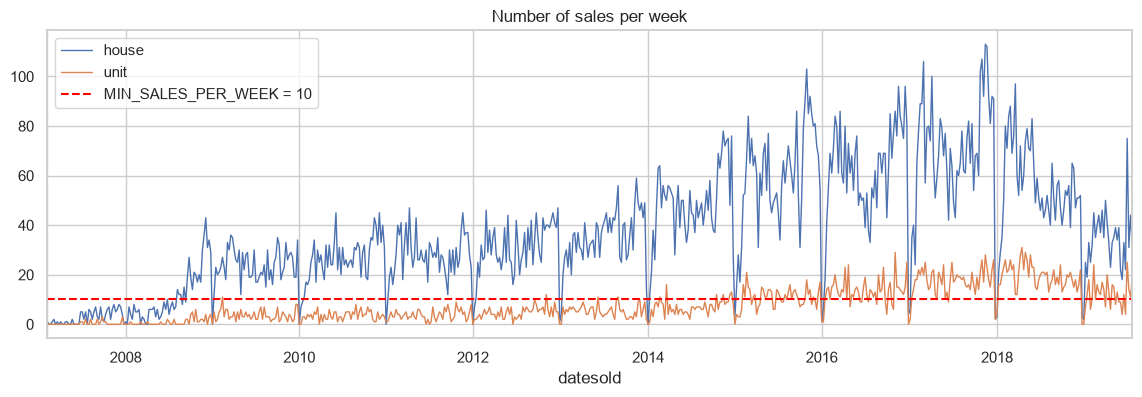

datesold,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
sales per year,147,639,1426,1555,1633,1858,2119,2863,3648,3908,4541,3858,1385


In [7]:
wk_counts = raw.set_index("datesold").groupby("propertyType").resample("W-SUN").size().unstack(0).fillna(0)
ax = wk_counts.plot(figsize=(14, 4), lw=1)
ax.axhline(MIN_SALES_PER_WEEK, color="red", ls="--", label=f"MIN_SALES_PER_WEEK = {MIN_SALES_PER_WEEK}")
ax.set_title("Number of sales per week")
ax.legend()
plt.show()
display(raw.groupby(raw["datesold"].dt.year).size().rename("sales per year").to_frame().T)

> ✍️ **Your observations (audit):** what is wrong or risky in the raw data, and which issues matter for building a weekly series?

## 3. Exploratory data analysis (transaction level)
### 3.1 Price distribution

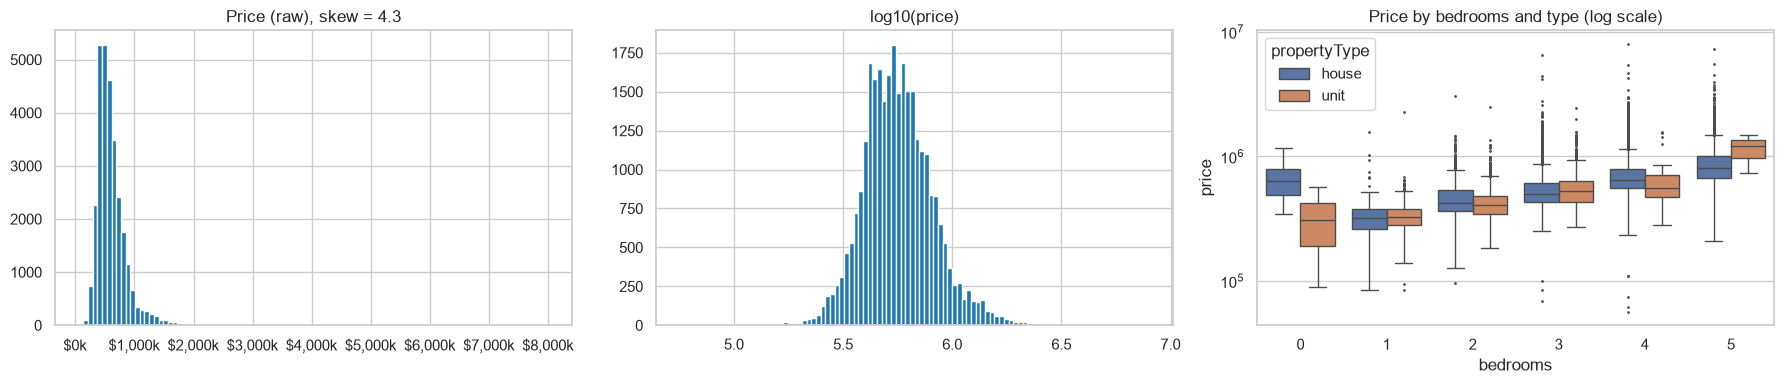

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(raw["price"], bins=100, color="tab:blue")
axes[0].set_title(f"Price (raw), skew = {raw['price'].skew():.1f}")
axes[0].xaxis.set_major_formatter(dollars)
axes[1].hist(np.log10(raw["price"]), bins=100, color="tab:blue")
axes[1].set_title("log10(price)")
sns.boxplot(data=raw, x="bedrooms", y="price", hue="propertyType", ax=axes[2], fliersize=1)
axes[2].set_yscale("log")
axes[2].set_title("Price by bedrooms and type (log scale)")
plt.tight_layout()
plt.show()

### 3.2 Price and volume over time

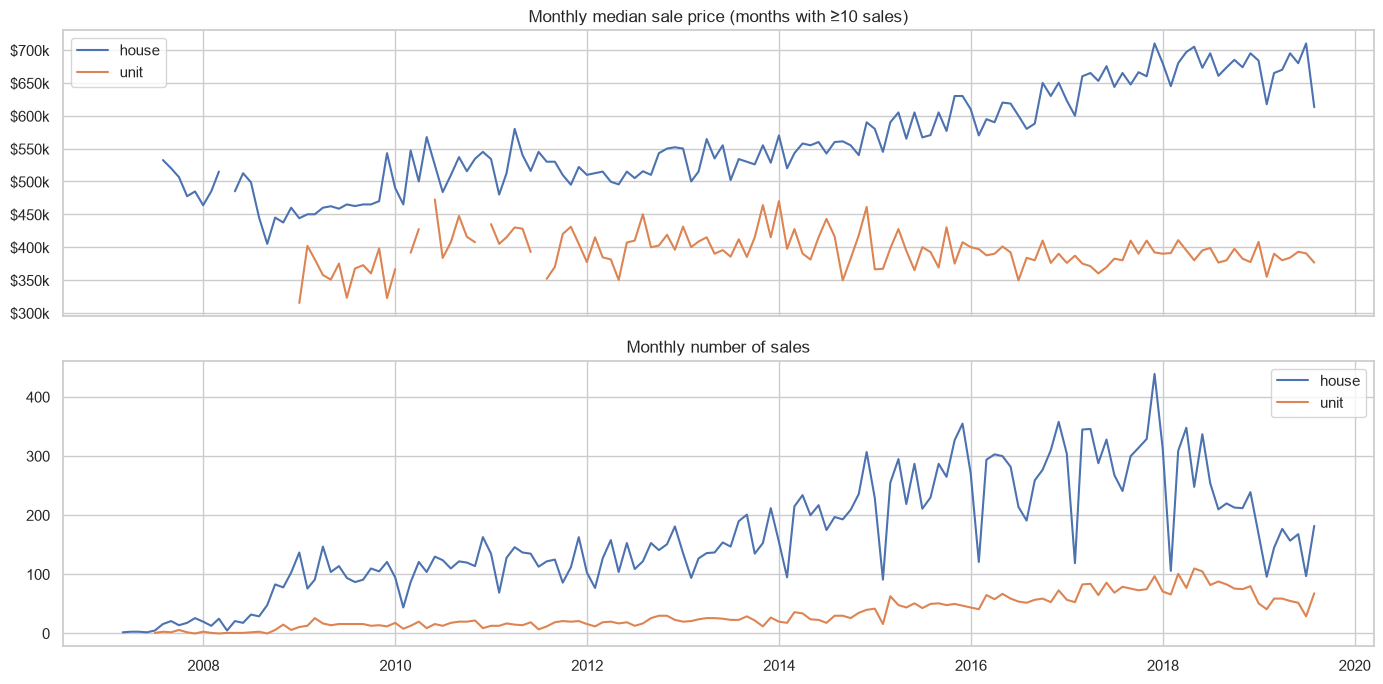

In [9]:
monthly = raw.set_index("datesold").groupby("propertyType").resample("ME")["price"].agg(["median", "size"])
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for t in ["house", "unit"]:
    m = monthly.loc[t]
    axes[0].plot(m.index, m["median"].where(m["size"] >= 10), label=t)
    axes[1].plot(m.index, m["size"], label=t)
axes[0].yaxis.set_major_formatter(dollars)
axes[0].set_title("Monthly median sale price (months with ≥10 sales)")
axes[0].legend()
axes[1].set_title("Monthly number of sales")
axes[1].legend()
plt.tight_layout()
plt.show()

### 3.3 Seasonality in when sales happen

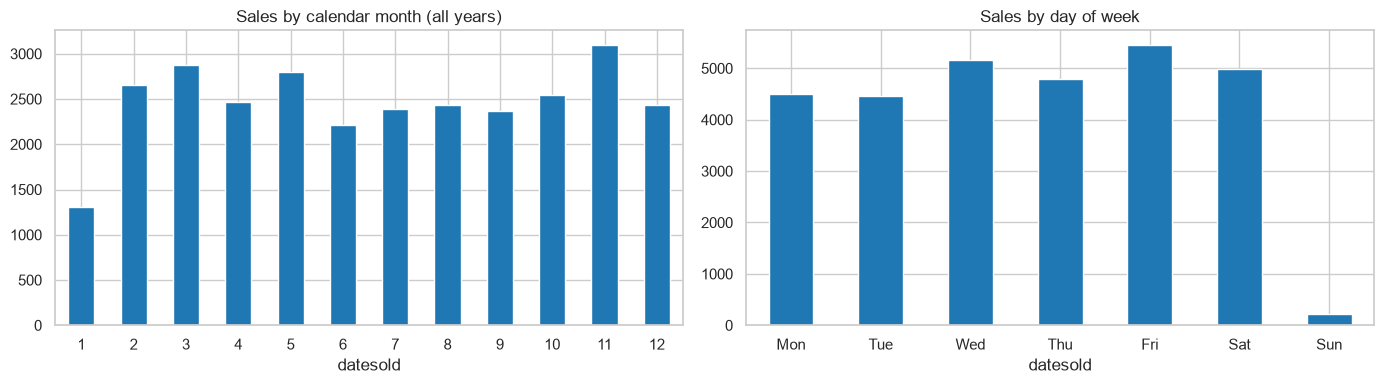

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
raw.groupby(raw["datesold"].dt.month).size().plot.bar(ax=axes[0], color="tab:blue", rot=0)
axes[0].set_title("Sales by calendar month (all years)")
raw.groupby(raw["datesold"].dt.dayofweek).size().rename(index=dict(enumerate("Mon Tue Wed Thu Fri Sat Sun".split()))) \
    .plot.bar(ax=axes[1], color="tab:blue", rot=0)
axes[1].set_title("Sales by day of week")
plt.tight_layout()
plt.show()

### 3.4 Geography: postcodes

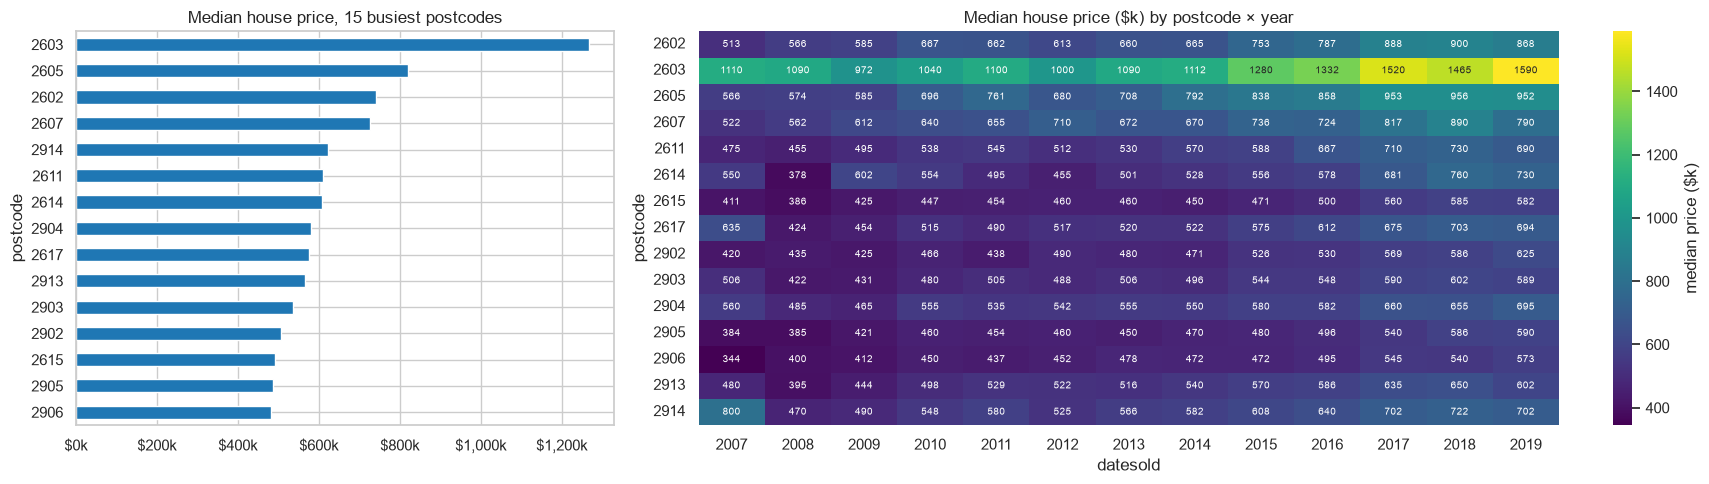

In [11]:
pc = raw[raw["propertyType"] == "house"].groupby("postcode")["price"].agg(["size", "median"]).sort_values("size", ascending=False)
top_pc = pc.head(15).index
heat = raw[(raw["propertyType"] == "house") & raw["postcode"].isin(top_pc)] \
    .pivot_table(index="postcode", columns=raw["datesold"].dt.year, values="price", aggfunc="median")
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 2]})
pc.head(15)["median"].sort_values().plot.barh(ax=axes[0], color="tab:blue")
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set_title("Median house price, 15 busiest postcodes")
sns.heatmap(heat / 1e3, cmap="viridis", ax=axes[1], annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "median price ($k)"})
axes[1].set_title("Median house price ($k) by postcode × year")
plt.tight_layout()
plt.show()

### 3.5 The publisher's moving-average series (`ma_lga_12345.csv`)

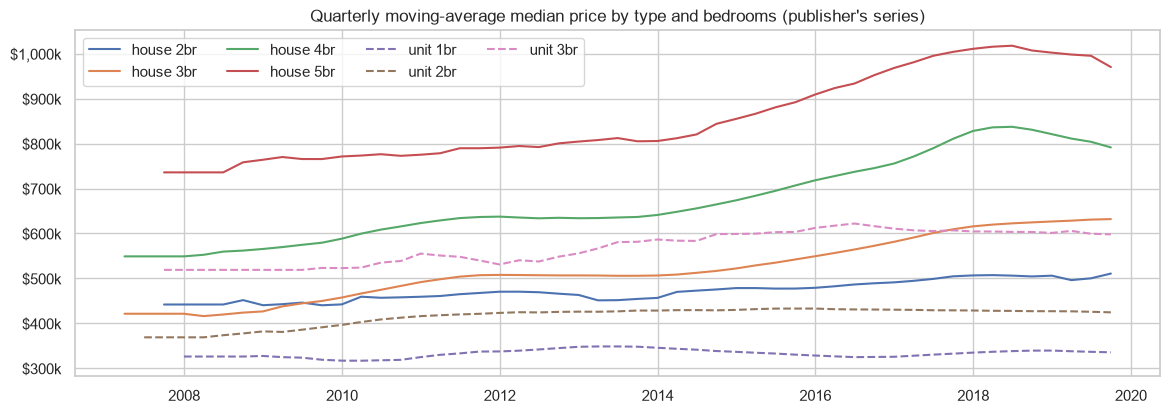

In [12]:
fig, ax = plt.subplots(figsize=(14, 4.5))
for (t, b), g in ma.groupby(["type", "bedrooms"]):
    ax.plot(g["saledate"], g["MA"], label=f"{t} {b}br", ls="-" if t == "house" else "--")
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Quarterly moving-average median price by type and bedrooms (publisher's series)")
ax.legend(ncol=4)
plt.show()

> ✍️ **Your observations (EDA):** describe the long-run trend, house vs unit gap, seasonality of sales volume, and how much prices differ by postcode.

## 4. Automated EDA with AutoViz

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (29580, 6)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  0
    Number of Integer-Categorical Columns =  2
    Number of String-Categorical Columns =  1
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  1
    Number of Numeric-Boolean Columns =  0
    Number of Discrete String Columns =  0
    Number of NLP String Columns =  0
    Number of

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
postcode,object,0.000000,0,,,"7 rare categories: ['2601', '2911', '2900', '2620', '2616', '2609', '2618']. Group them into a single category or drop the categories."
propertyType,object,0.000000,0,,,No issue
bedrooms,int64,0.000000,0,0.000000,5.000000,Column has 1636 outliers greater than upper bound (5.50) or lower than lower bound(1.50). Cap them or remove them.
year,int32,0.000000,0,2007.000000,2019.000000,Possible date-time colum: transform before modeling step.
month,int32,0.000000,0,1.000000,12.000000,No issue
price,int64,0.000000,8,56500.000000,8000000.000000,Target column


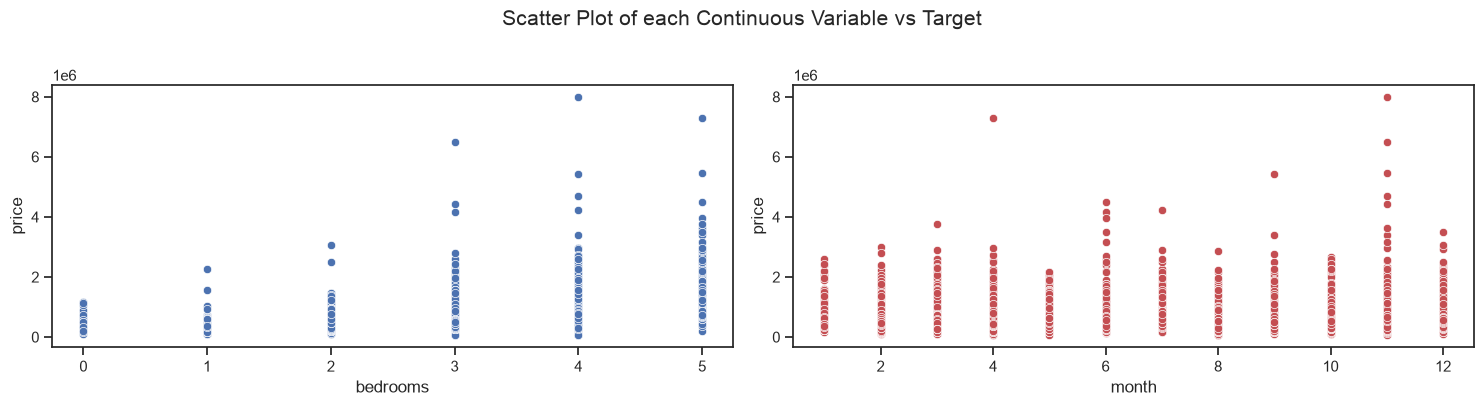

Number of All Scatter Plots = 3


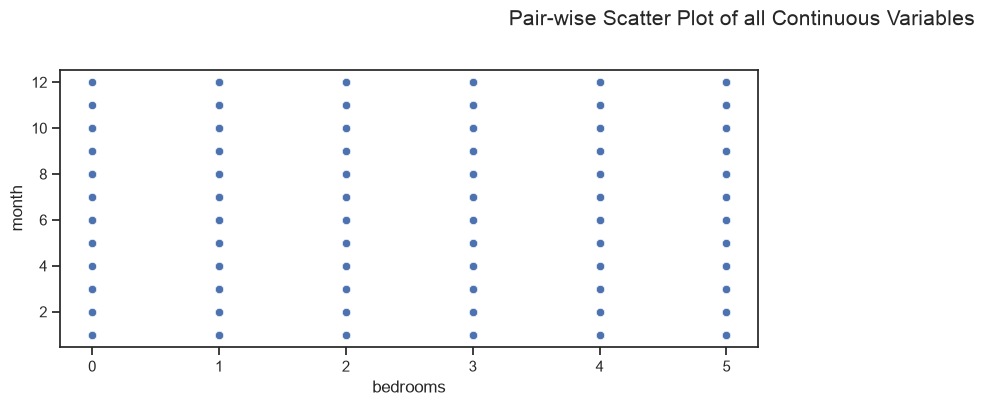

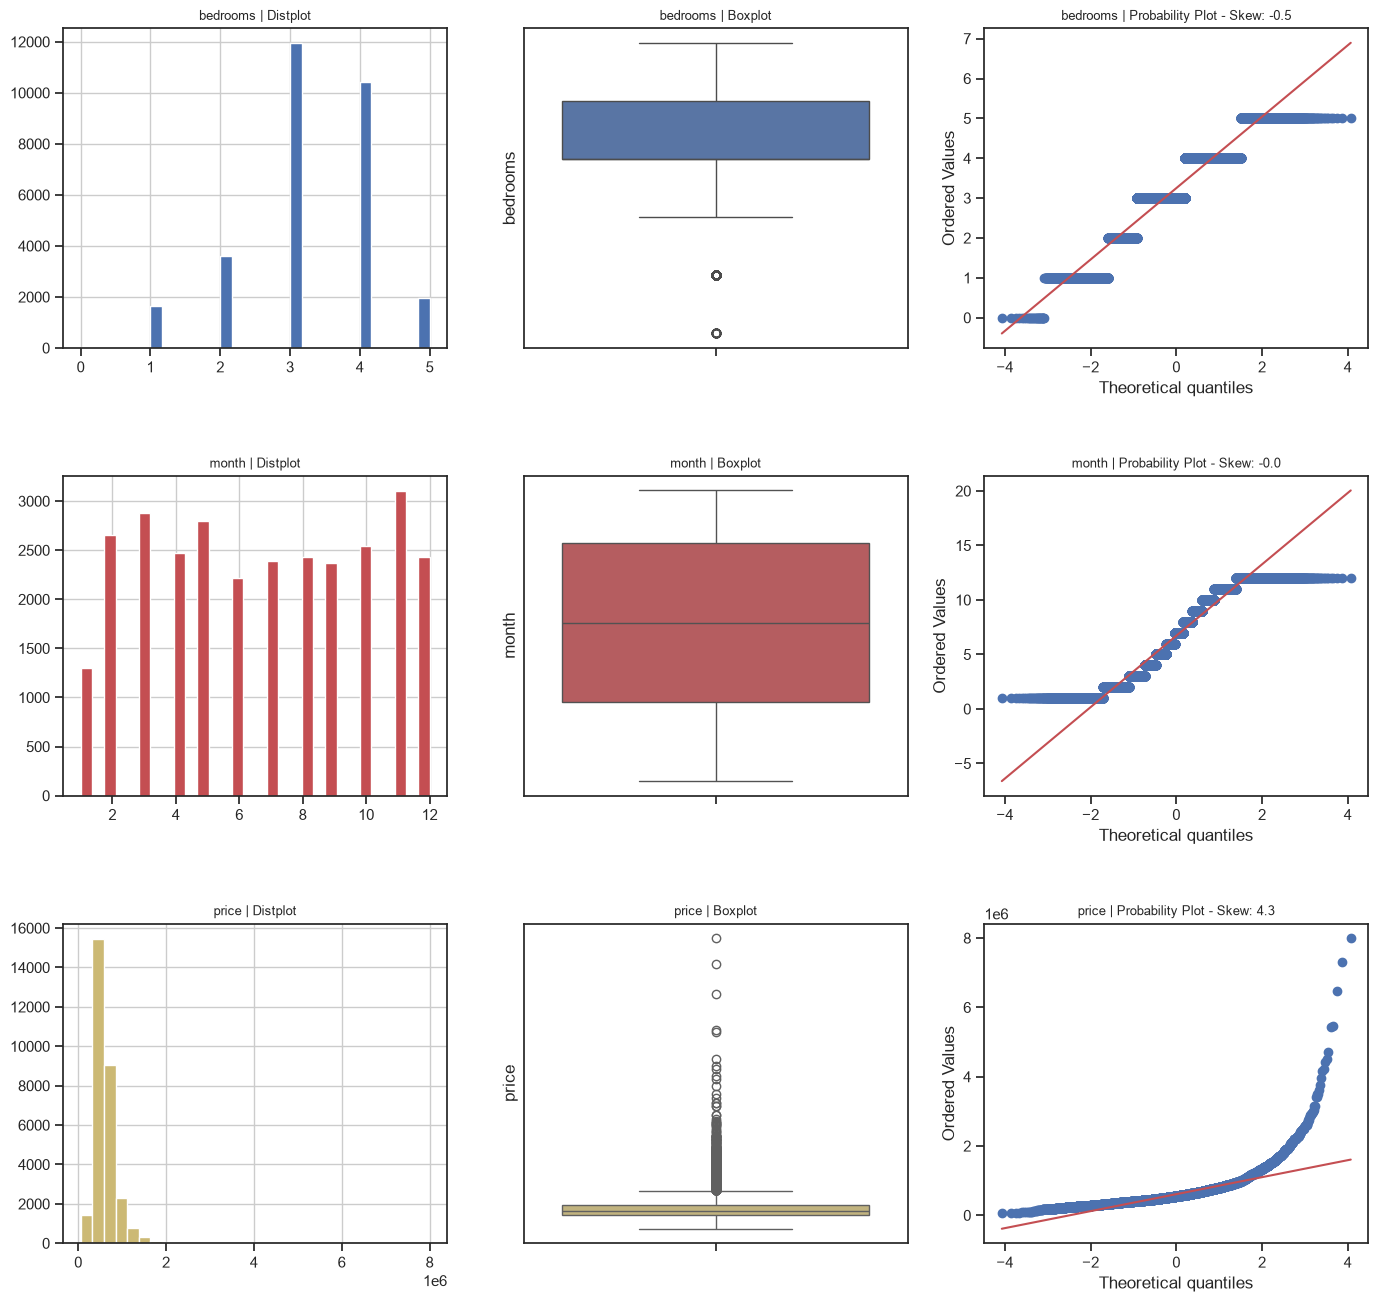

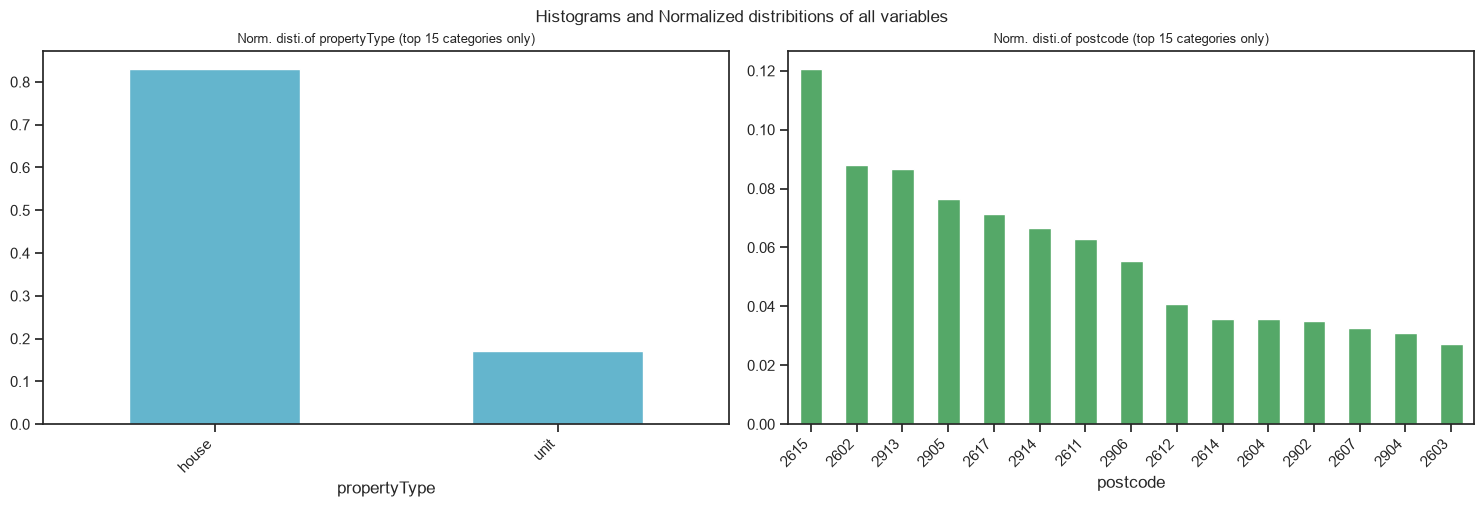

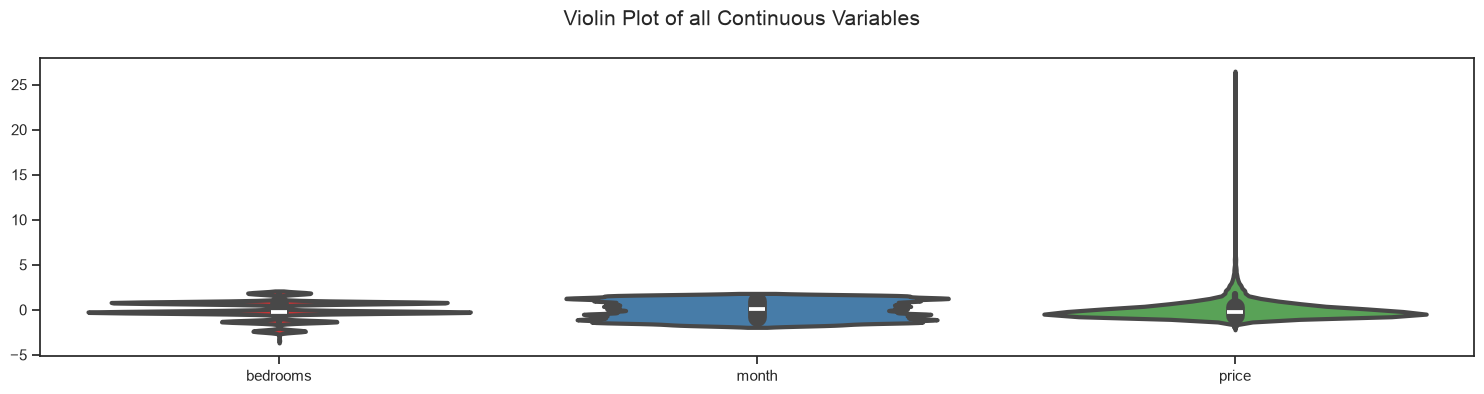

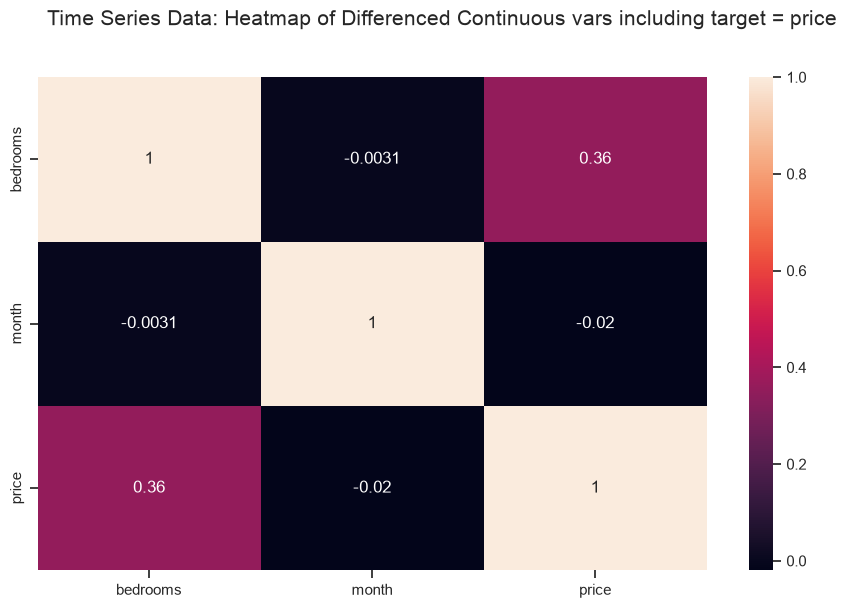

Could not draw some Time Series plots. agg function failed [how->mean,dtype->object]


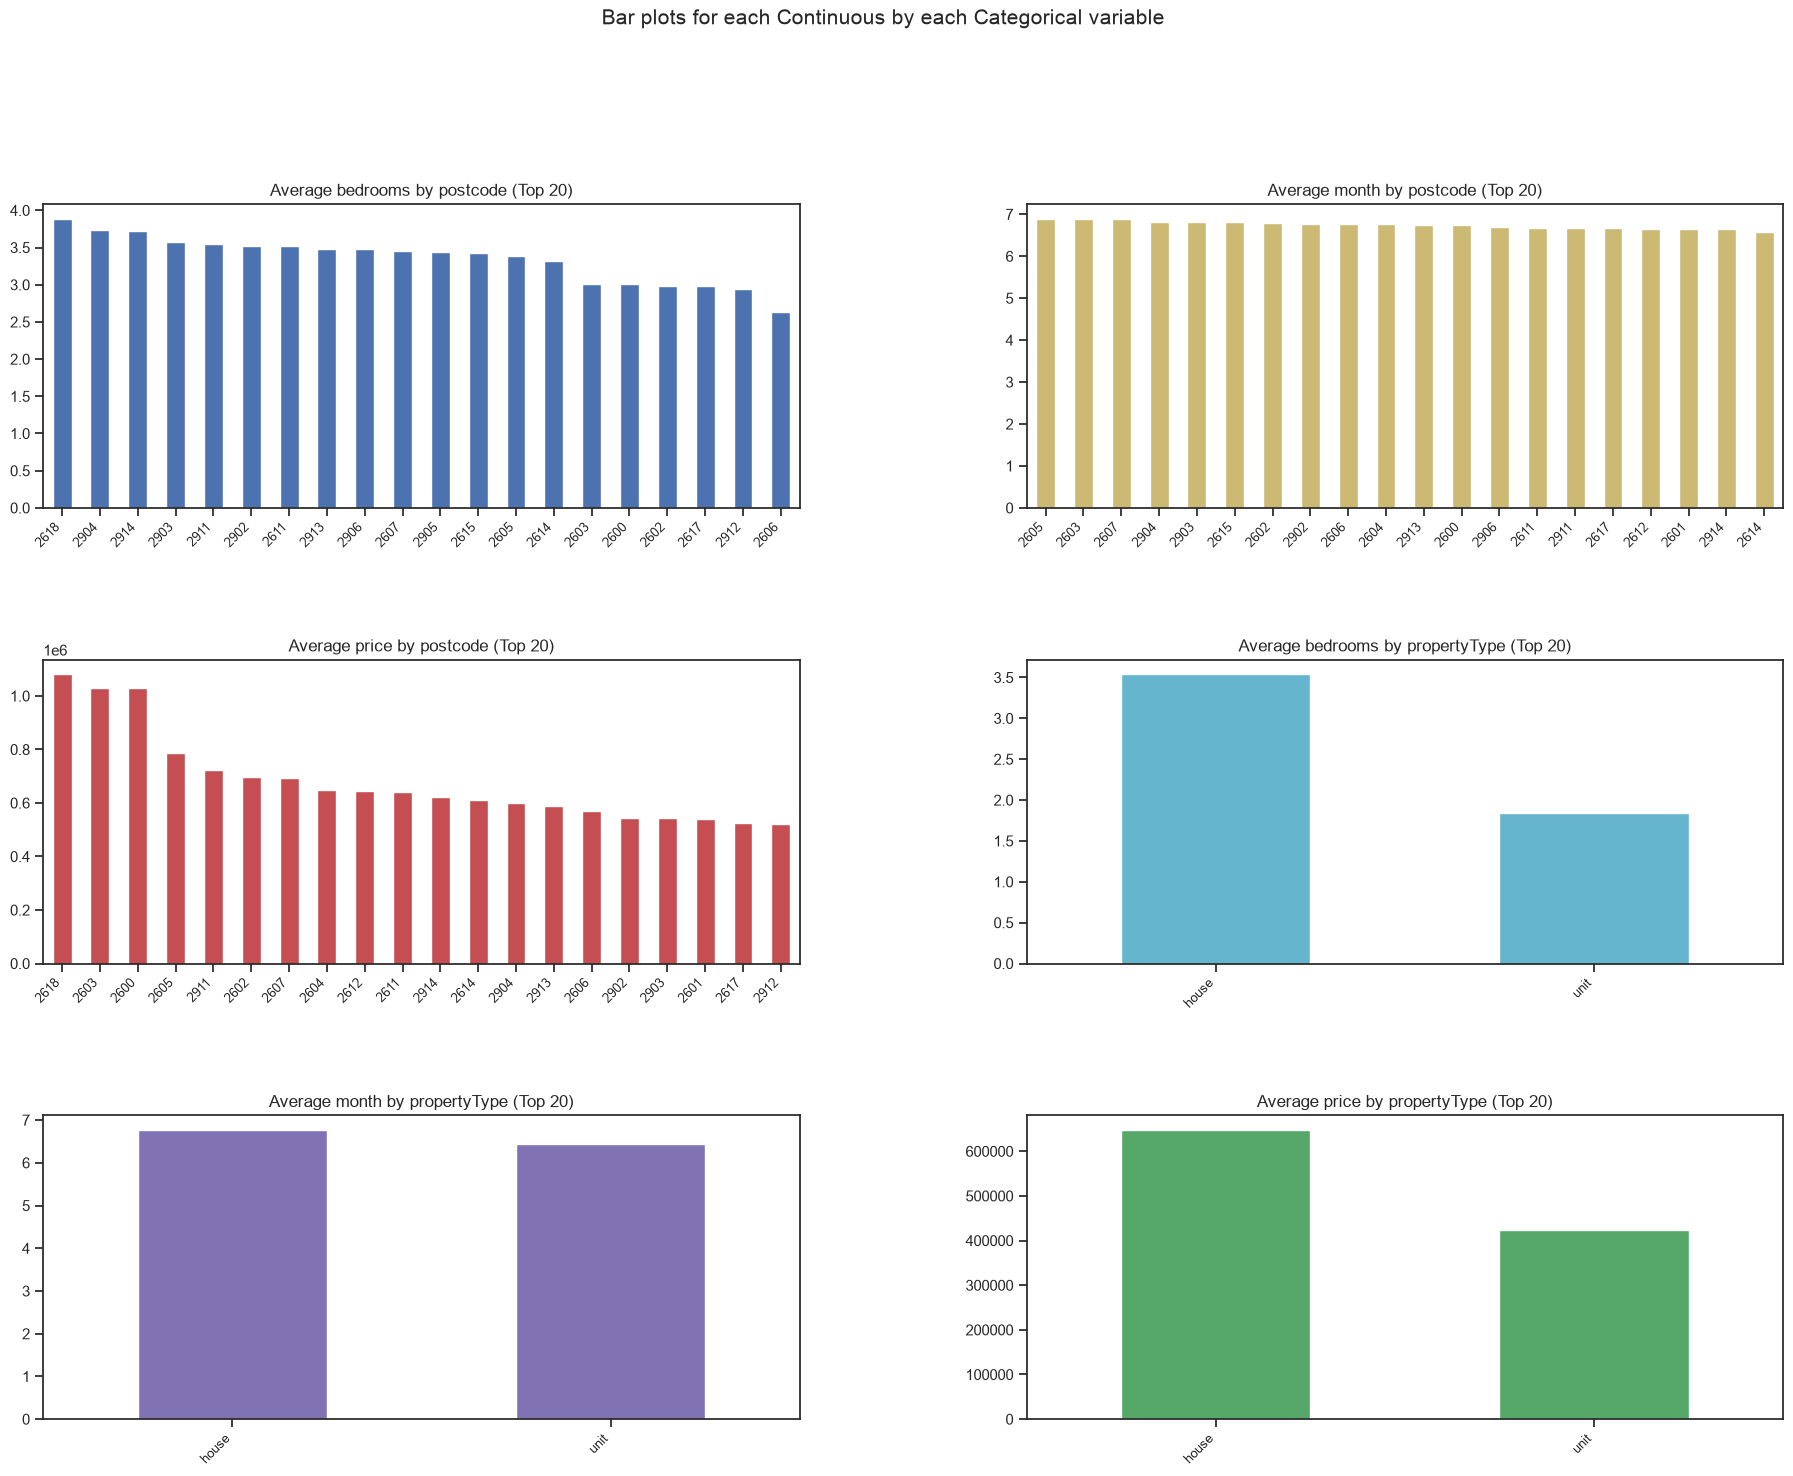

All Plots done
Time to run AutoViz = 2 seconds 

 ###################### AUTO VISUALIZATION Completed ########################


In [13]:
if RUN_AUTOVIZ:
    from autoviz import AutoViz_Class
    %matplotlib inline
    # NB: importing autoviz switches matplotlib to the non-interactive 'agg' backend, so inline plotting is
    # re-enabled straight after the import (and again below for the rest of the notebook).
    AV = AutoViz_Class()
    av_df = raw.assign(year=raw["datesold"].dt.year, month=raw["datesold"].dt.month,
                       postcode=raw["postcode"].astype(str)).drop(columns="datesold")
    _ = AV.AutoViz(filename="", dfte=av_df, depVar="price", verbose=1, chart_format="png",
                   max_rows_analyzed=30000, max_cols_analyzed=10)
%matplotlib inline

> ✍️ **Your observations (AutoViz vs manual):** what did AutoViz flag (skew, outliers, high-cardinality postcode)? What can't it see because it ignores time ordering?

## 5. Transaction-level cleaning
### 5.1 Duplicates and types

In [14]:
clean_log = []


def log_step(step, before, after, reason):
    clean_log.append({"step": step, "rows_before": before, "rows_after": after,
                      "rows_removed": before - after, "reason": reason})


tx = raw.sort_values("datesold").reset_index(drop=True).copy()
n = len(tx); tx = tx.drop_duplicates()
log_step("Drop exact duplicates", n, len(tx), "double-recorded sales")
tx["postcode"] = tx["postcode"].astype(str)          # a postcode is a label, not a number
tx["log_price"] = np.log(tx["price"])
tx["year"] = tx["datesold"].dt.year
tx["t"] = tx["datesold"].dt.year + tx["datesold"].dt.dayofyear / 366   # decimal year
log_step("postcode → string; add log_price, year, decimal time", len(tx), len(tx), "correct types for analysis")

### 5.2 Imputing implausible bedroom counts (KNN)
A *house* with 0 bedrooms is a data-entry error. These values are set to missing and imputed with a **KNN classifier** trained on other houses, using log price, sale time and the postcode's typical price level. Similar houses sold at a similar price, place and time most likely have the same number of bedrooms.

In [15]:
bad_bed = (tx["propertyType"] == "house") & (tx["bedrooms"] == 0)
tx.loc[bad_bed, "bedrooms"] = np.nan
houses_known = tx[(tx["propertyType"] == "house") & tx["bedrooms"].notna()]
pc_level = houses_known.groupby("postcode")["log_price"].median()


def bed_features(d):
    return np.column_stack([d["log_price"], d["t"], d["postcode"].map(pc_level).fillna(pc_level.median())])


bed_scaler = StandardScaler().fit(bed_features(houses_known))
knn_bed = KNeighborsClassifier(n_neighbors=15).fit(bed_scaler.transform(bed_features(houses_known)),
                                                   houses_known["bedrooms"].astype(int))
tx.loc[bad_bed, "bedrooms"] = knn_bed.predict(bed_scaler.transform(bed_features(tx[bad_bed])))
tx["bedrooms"] = tx["bedrooms"].astype(int)
display(tx.loc[bad_bed, ["datesold", "postcode", "price", "bedrooms"]].head(10))
log_step("House bedrooms 0 → KNN-imputed", len(tx), len(tx), f"{bad_bed.sum()} implausible values")

,datesold,postcode,price,bedrooms
6583,2012-09-10,2913,415000,3
7382,2013-02-02,2605,840000,4
7401,2013-02-06,2604,490000,3
7892,2013-05-07,2600,725000,3
8184,2013-06-28,2606,630000,3
8316,2013-07-18,2602,620000,3
8513,2013-08-17,2617,543000,3
11995,2014-12-03,2615,405000,3
12312,2015-01-27,2906,525000,4
12342,2015-01-31,2602,700000,3


### 5.3 Price anomalies: modified z-score within comparable groups
One $8M sale is not an outlier in the same way for a 5-bedroom house in 2019 as for a 2-bedroom unit in 2008. So anomalies are judged **within peer groups** (type × bedrooms × year) using the robust **modified z-score** (Iglewicz & Hoaglin):

$$ M_i = 0.6745\,\frac{x_i - \operatorname{median}(x)}{\operatorname{MAD}} \qquad |M_i| > 3.5 \Rightarrow \text{anomaly} $$

It is applied to log price. Groups with fewer than 20 sales are not judged because the MAD is unreliable there. An **Isolation Forest** (multivariate) is run as a cross-check.

isolation forest,False,True
modified z,,
False,28625,243
True,659,53


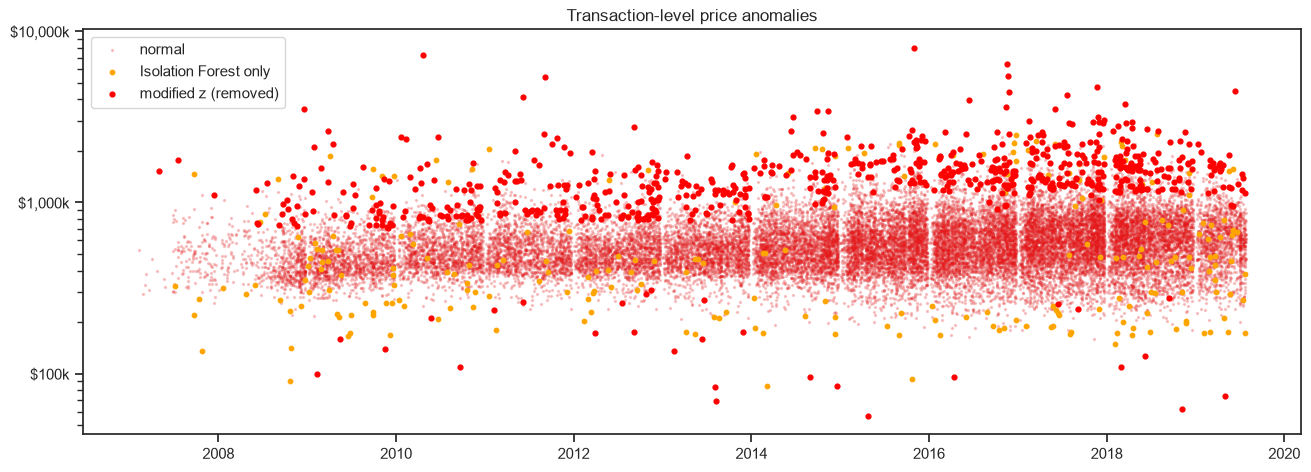

,datesold,postcode,propertyType,bedrooms,price,mod_z
27714,2018-11-06,2615,house,4,62000,-12.602322
29011,2019-05-03,2912,house,4,74000,-10.980193
8441,2013-08-07,2605,house,3,69000,-10.844674
13215,2015-04-24,2611,house,4,56500,-9.862809
926,2009-02-11,2905,house,3,100000,-9.726341
8433,2013-08-06,2600,house,3,84000,-9.722767
24923,2018-03-01,2605,house,4,110000,-9.720392
3264,2010-09-21,2606,house,4,110000,-8.718794


,datesold,postcode,propertyType,bedrooms,price,mod_z
29243,2019-06-13,2603,house,5,4500000,8.988128
19387,2016-11-26,2600,house,3,4417000,9.154226
24245,2017-12-20,2603,house,2,3050000,9.312432
15186,2015-11-02,2611,house,4,8000000,10.135319
19273,2016-11-19,2611,house,3,6480000,10.779406
4878,2011-09-07,2912,house,4,5425000,10.920396
1124,2009-03-25,2603,house,3,2600000,12.541365
4481,2011-06-06,2902,house,3,4150000,12.673684


In [16]:
grp = tx.groupby(["propertyType", "bedrooms", "year"])["log_price"]
g_med = grp.transform("median")
g_mad = grp.transform(lambda s: (s - s.median()).abs().median())
g_n = grp.transform("size")
tx["mod_z"] = (0.6745 * (tx["log_price"] - g_med) / g_mad.replace(0, np.nan)).where(g_n >= 20)
tx["anom_mz"] = tx["mod_z"].abs() > 3.5

iso_X = StandardScaler().fit_transform(np.column_stack([
    tx["log_price"], tx["bedrooms"], (tx["propertyType"] == "house").astype(int), tx["t"],
    tx["postcode"].map(tx.groupby("postcode")["log_price"].median())]))
tx["anom_iso"] = IsolationForest(n_estimators=300, contamination=0.01, random_state=RANDOM_STATE).fit_predict(iso_X) == -1
display(pd.crosstab(tx["anom_mz"], tx["anom_iso"], rownames=["modified z"], colnames=["isolation forest"]))

fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(tx["datesold"], tx["price"], s=2, alpha=.2, label="normal")
ax.scatter(tx.loc[tx["anom_iso"] & ~tx["anom_mz"], "datesold"], tx.loc[tx["anom_iso"] & ~tx["anom_mz"], "price"],
           s=10, c="orange", label="Isolation Forest only")
ax.scatter(tx.loc[tx["anom_mz"], "datesold"], tx.loc[tx["anom_mz"], "price"], s=12, c="red", label="modified z (removed)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Transaction-level price anomalies")
ax.legend()
plt.show()
display(tx[tx["anom_mz"]].sort_values("mod_z")[["datesold", "postcode", "propertyType", "bedrooms", "price", "mod_z"]].head(8))
display(tx[tx["anom_mz"]].sort_values("mod_z")[["datesold", "postcode", "propertyType", "bedrooms", "price", "mod_z"]].tail(8))

The modified-z flags are removed because they are explainable ("this sale is far from its peer group"). The Isolation Forest also flags many sales that are merely **old and cheap** or **new and expensive**. Those are real market extremes rather than errors, so they are kept.

In [17]:
n = len(tx)
tx = tx[~tx["anom_mz"]].drop(columns=["anom_mz", "anom_iso", "mod_z"])
log_step("Remove peer-group price anomalies (|M|>3.5)", n, len(tx), "data-entry errors / non-standard sales")
pd.DataFrame(clean_log)

,step,rows_before,rows_after,rows_removed,reason
0,Drop exact duplicates,29580,29580,0,double-recorded sales
1,"postcode → string; add log_price, year, decimal time",29580,29580,0,correct types for analysis
2,House bedrooms 0 → KNN-imputed,29580,29580,0,19 implausible values
3,Remove peer-group price anomalies (|M|>3.5),29580,28868,712,data-entry errors / non-standard sales


## 6. Build the weekly series
* **Target series:** weekly median **house** price (houses are about 80% of sales and a different market from units).
* Weeks end on Sunday. The **start** is the first week from which the 8-week rolling median of sales stays ≥ `MIN_SALES_PER_WEEK`, and the final **partial** week is dropped.
* Weeks with fewer than `MIN_SALES_PER_WEEK` sales (e.g. the Christmas break) get a **missing** median, because a median of 2 or 3 sales is mostly noise. These gaps are imputed in section 7.

In [18]:
houses = tx[tx["propertyType"] == "house"].set_index("datesold")
weekly = pd.DataFrame({"median_price": houses["price"].resample("W-SUN").median(),
                       "n_sales": houses["price"].resample("W-SUN").size()})

roll_ok = weekly["n_sales"].rolling(8).median() >= MIN_SALES_PER_WEEK
START_DATE = roll_ok[roll_ok].index.min()
if tx["datesold"].max() < weekly.index[-1]:
    weekly = weekly.iloc[:-1]                                                # drop the partial final week
weekly = weekly.loc[START_DATE:]

weekly["observed"] = weekly["n_sales"] >= MIN_SALES_PER_WEEK
weekly.loc[~weekly["observed"], "median_price"] = np.nan
print(f"Series: {weekly.index.min().date()} → {weekly.index.max().date()}, {len(weekly)} weeks")
print(f"Missing (low-count) weeks: {(~weekly['observed']).sum()}")
display(weekly[~weekly["observed"]].head(12))

Series: 2008-09-07 → 2019-07-21, 568 weeks
Missing (low-count) weeks: 21


,median_price,n_sales,observed
datesold,,,
2008-09-14,NaN,8,False
2009-01-04,NaN,0,False
2010-01-03,NaN,0,False
2010-01-10,NaN,7,False
2010-01-17,NaN,9,False
2011-01-02,NaN,0,False
2011-01-09,NaN,9,False
2012-01-01,NaN,0,False
2012-01-08,NaN,7,False


### 6.1 Chronological train/test split
The split date is fixed **before** any imputation or anomaly handling, so nothing learned from the test period can influence training.

Train: 2008-09-07 → 2017-05-14 (454 weeks)
Test:  2017-05-21 → 2019-07-21 (114 weeks)


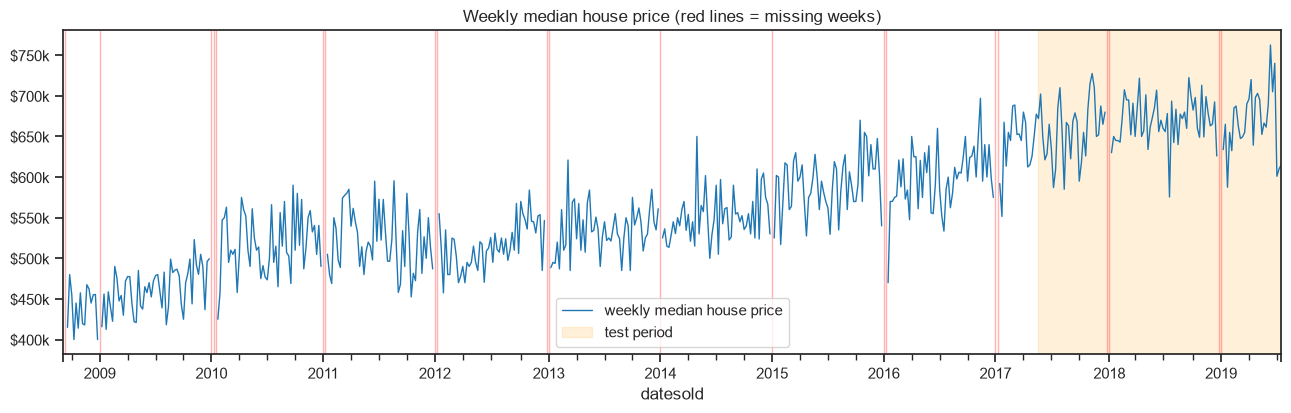

In [19]:
SPLIT_DATE = weekly.index[int(len(weekly) * (1 - TEST_FRACTION))]
is_train = weekly.index < SPLIT_DATE
print(f"Train: {weekly.index[is_train].min().date()} → {weekly.index[is_train].max().date()} ({is_train.sum()} weeks)")
print(f"Test:  {SPLIT_DATE.date()} → {weekly.index.max().date()} ({(~is_train).sum()} weeks)")

ax = weekly["median_price"].plot(figsize=(14, 4), lw=1, color="tab:blue", label="weekly median house price")
ax.axvspan(SPLIT_DATE, weekly.index.max(), color="orange", alpha=.15, label="test period")
for d in weekly.index[~weekly["observed"]]:
    ax.axvline(d, color="red", alpha=.3, lw=1)
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Weekly median house price (red lines = missing weeks)")
ax.legend()
plt.show()

## 7. Imputation of missing weeks
Candidate methods are evaluated by **hiding 10% of the observed training weeks**, imputing them and measuring the error:
* **Forward fill**: repeat last week's value (strictly causal)
* **Linear interpolation** between the neighbouring weeks
* **Centred rolling median** (9-week window)

The winner is applied to train and test **separately**, so no value from the test period is used to fill a training week, and the other way round.

In [20]:
def impute_series(s, method):
    if method == "ffill":
        return s.ffill().bfill()
    if method == "linear":
        return s.interpolate("linear").ffill().bfill()
    if method == "rolling_median":
        return s.fillna(s.rolling(9, center=True, min_periods=1).median()).ffill().bfill()
    raise ValueError(method)


y_tr = weekly.loc[is_train, "median_price"]
obs_idx = y_tr.dropna().index
mask = pd.Index(np.random.default_rng(RANDOM_STATE).choice(obs_idx, size=int(0.1 * len(obs_idx)), replace=False))
masked = y_tr.copy()
masked[mask] = np.nan
imp_res = pd.DataFrame({m: {"MAE": mean_absolute_error(y_tr[mask], impute_series(masked, m)[mask]),
                            "RMSE": np.sqrt(mean_squared_error(y_tr[mask], impute_series(masked, m)[mask]))}
                        for m in ["ffill", "linear", "rolling_median"]}).T.sort_values("MAE")
BEST_IMPUTER = imp_res.index[0]
display(imp_res.round(0))
print("Selected imputer:", BEST_IMPUTER)

weekly["price_clean"] = pd.concat([impute_series(weekly.loc[is_train, "median_price"], BEST_IMPUTER),
                                   impute_series(weekly.loc[~is_train, "median_price"], BEST_IMPUTER)])
assert weekly["price_clean"].notna().all()

,MAE,RMSE
rolling_median,27428.0,34512.0
linear,31012.0,38226.0
ffill,34822.0,43776.0


Selected imputer: rolling_median


## 8. Time-series EDA
### 8.1 Rolling statistics

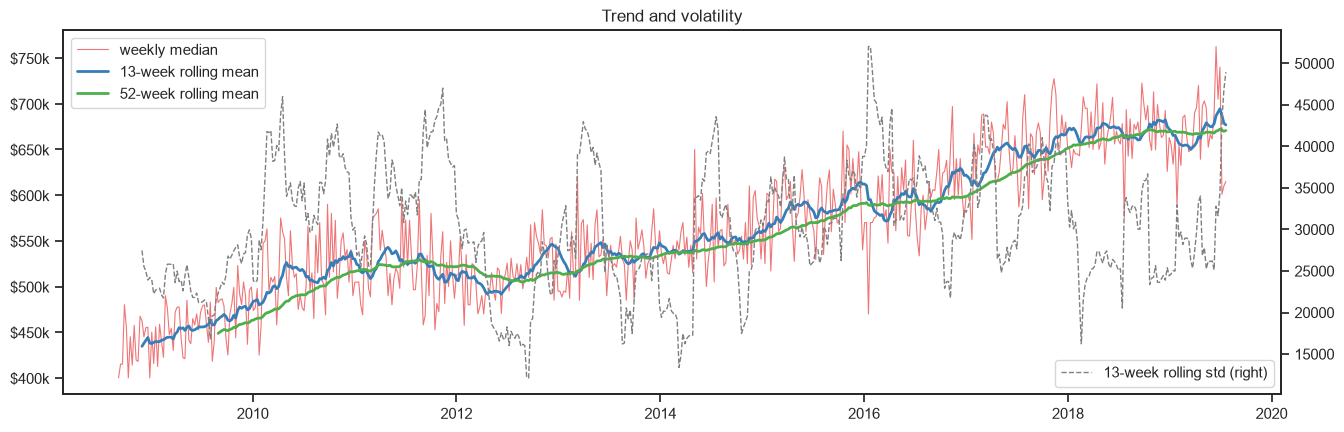

In [21]:
y = weekly["price_clean"]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(y, lw=.8, alpha=.6, label="weekly median")
ax.plot(y.rolling(13).mean(), lw=2, label="13-week rolling mean")
ax.plot(y.rolling(52).mean(), lw=2, label="52-week rolling mean")
ax2 = ax.twinx()
ax2.plot(y.rolling(13).std(), color="grey", lw=1, ls="--", label="13-week rolling std (right)")
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Trend and volatility")
ax.legend(loc="upper left")
ax2.legend(loc="lower right")
plt.show()

### 8.2 STL decomposition (trend + yearly seasonality + residual)

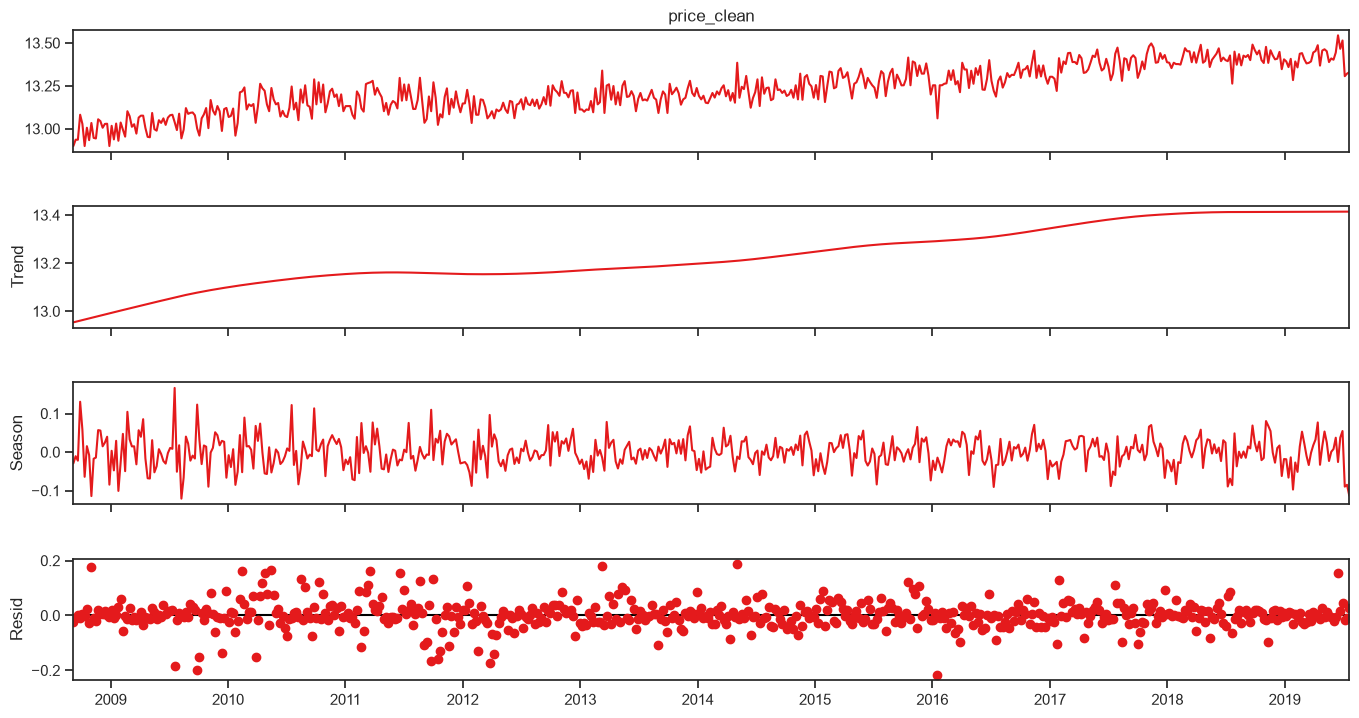

Strength of trend: 0.86 | strength of yearly seasonality: 0.24  (0 = none, 1 = dominant)


In [22]:
stl_full = STL(np.log(y), period=52, robust=True).fit()
fig = stl_full.plot()
fig.set_size_inches(14, 8)
plt.show()
strength_trend = max(0, 1 - stl_full.resid.var() / (stl_full.trend + stl_full.resid).var())
strength_season = max(0, 1 - stl_full.resid.var() / (stl_full.seasonal + stl_full.resid).var())
print(f"Strength of trend: {strength_trend:.2f} | strength of yearly seasonality: {strength_season:.2f}  (0 = none, 1 = dominant)")

### 8.3 Stationarity (Augmented Dickey-Fuller) and autocorrelation

,series,ADF statistic,p-value,stationary (p<0.05)
0,price level,-1.096,0.7168,False
1,"log price, 1st difference",-10.407,0.0000,True
2,price / trailing 13-wk mean − 1 (our target),-9.498,0.0000,True


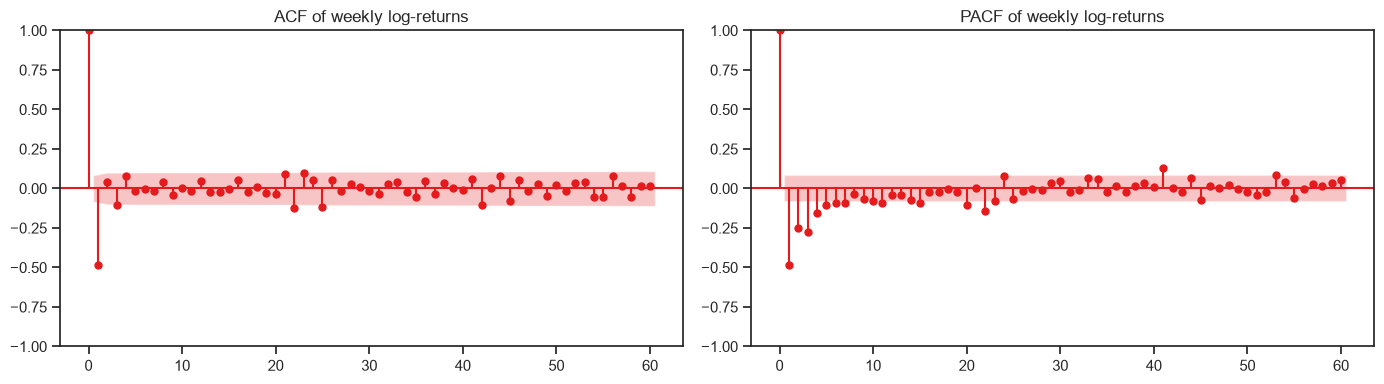

In [23]:
def adf_row(s, name):
    stat, p, *_ = adfuller(s.dropna(), autolag="AIC")
    return {"series": name, "ADF statistic": round(stat, 3), "p-value": round(p, 4), "stationary (p<0.05)": p < 0.05}


rel13 = y / y.shift(1).rolling(13).mean() - 1
display(pd.DataFrame([adf_row(y, "price level"), adf_row(np.log(y).diff(), "log price, 1st difference"),
                      adf_row(rel13, "price / trailing 13-wk mean − 1  (our target)")]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(np.log(y).diff().dropna(), lags=60, ax=axes[0])
plot_pacf(np.log(y).diff().dropna(), lags=60, ax=axes[1], method="ywm")
axes[0].set_title("ACF of weekly log-returns")
axes[1].set_title("PACF of weekly log-returns")
plt.tight_layout()
plt.show()

### 8.4 Sanity check against the publisher's series
The quarterly median of **our cleaned** 3-bedroom house data is compared with the publisher's moving average (`ma_lga`). If they agree, the cleaning didn't distort the market signal.

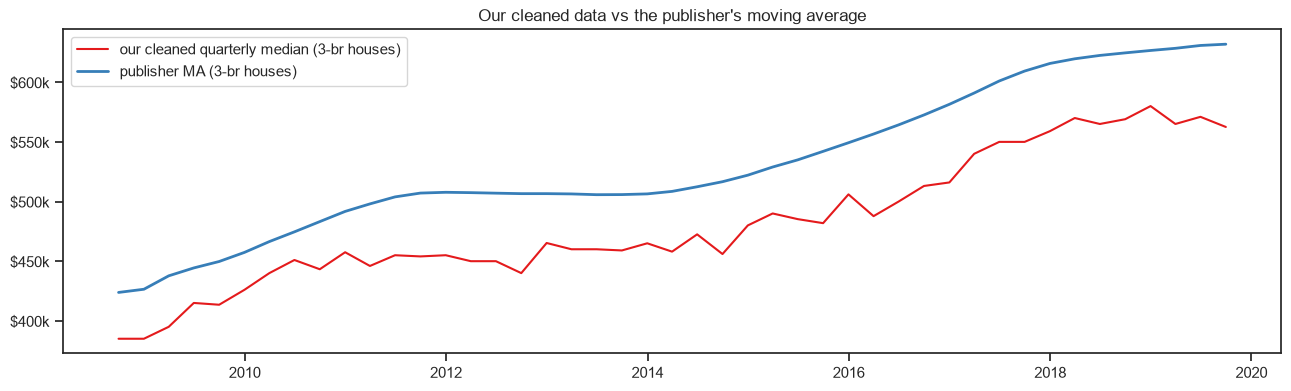

Correlation of the two quarterly series: 0.916


In [24]:
ours = tx[(tx["propertyType"] == "house") & (tx["bedrooms"] == 3)].set_index("datesold")["price"].resample("QE").median()
theirs = ma[(ma["type"] == "house") & (ma["bedrooms"] == 3)].set_index("saledate")["MA"]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ours.loc[START_DATE:], label="our cleaned quarterly median (3-br houses)")
ax.plot(theirs.loc[START_DATE:], label="publisher MA (3-br houses)", lw=2)
ax.yaxis.set_major_formatter(dollars)
ax.legend()
ax.set_title("Our cleaned data vs the publisher's moving average")
plt.show()
both = pd.concat([ours, theirs], axis=1, keys=["ours", "theirs"]).dropna()
print(f"Correlation of the two quarterly series: {both.corr().iloc[0, 1]:.3f}")

> ✍️ **Your observations (time-series EDA):** how strong are the trend and seasonality? Is the price level stationary, and does the relative target fix that? What do ACF and PACF say about how many lags matter?

## 9. Series-level anomaly removal (training period only)
Even after transaction cleaning, a week can be unusual (e.g. a few luxury sales in a low-volume week). These are found as large residuals of a **robust STL** decomposition, **fit on the training period only**, using a 3σ rule on the residual of log price.

*Why 3σ and not the modified z-score used in 5.3?* Robust STL deliberately leaves outliers in the residual, which makes the residual's MAD very small. A MAD-based rule would then flag about 6% of all weeks. The 3σ rule flags about 2%, which matches what the plot shows by eye.

Flagged weeks are replaced with the chosen imputer. The test period is left as observed, so the model is evaluated on reality.

11 anomalous training weeks: ['2008-11-02', '2009-07-19', '2009-09-27', '2010-05-16', '2011-03-20', '2011-09-25', '2011-10-16', '2012-03-25', '2013-03-10', '2014-05-04', '2016-01-17']


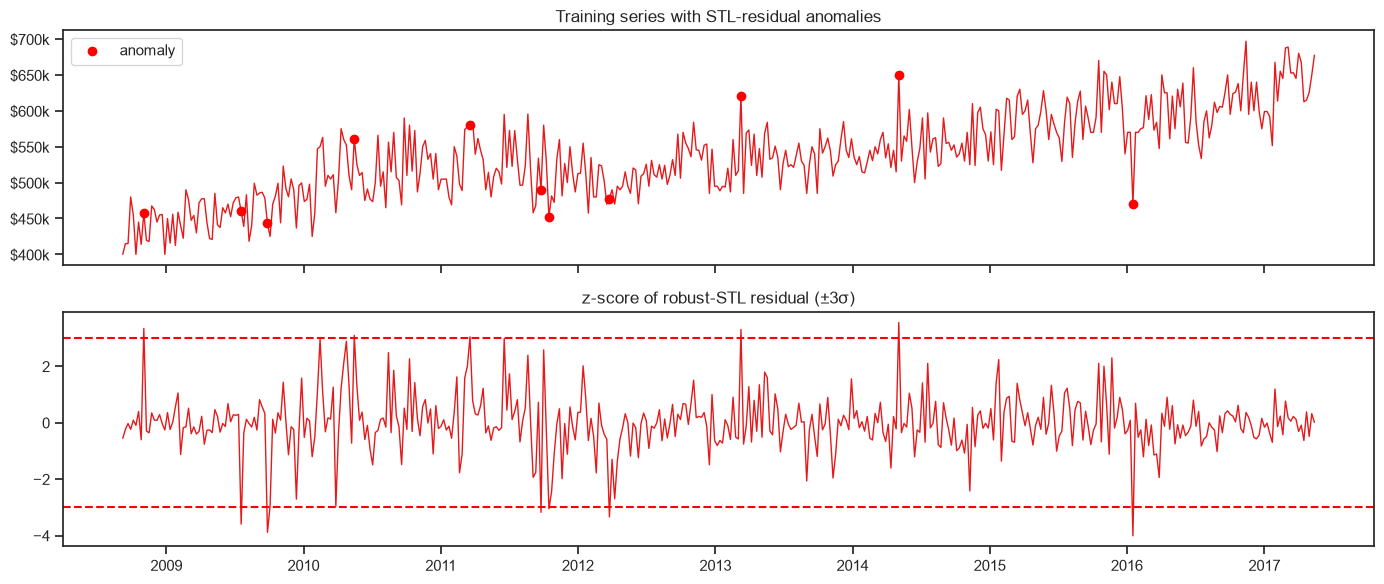

In [25]:
y_train = weekly.loc[is_train, "price_clean"]
stl_tr = STL(np.log(y_train), period=52, robust=True).fit()
r = stl_tr.resid
rz = (r - r.mean()) / r.std()
anom_weeks = rz.index[rz.abs() > 3]
print(f"{len(anom_weeks)} anomalous training weeks:", [d.date().isoformat() for d in anom_weeks])

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(y_train, lw=1)
axes[0].scatter(anom_weeks, y_train[anom_weeks], c="red", zorder=3, label="anomaly")
axes[0].yaxis.set_major_formatter(dollars)
axes[0].legend()
axes[0].set_title("Training series with STL-residual anomalies")
axes[1].plot(rz, lw=1)
axes[1].axhline(3, c="red", ls="--")
axes[1].axhline(-3, c="red", ls="--")
axes[1].set_title("z-score of robust-STL residual (±3σ)")
plt.tight_layout()
plt.show()

fixed = y_train.copy()
fixed[anom_weeks] = np.nan
weekly.loc[is_train, "price_clean"] = impute_series(fixed, BEST_IMPUTER)

## 10. Clustering: postcodes by price trajectory
Do all suburbs move together? Each postcode is described by its **price-growth curve** (yearly median house price indexed to its first training year = 1) plus its **price level**, using **training years only**. These are clustered with K-Means (*k* by silhouette). The clusters
1. give an insight: which areas boomed and which lagged, and
2. become **features**: last week's median price in each postcode cluster tells the model *where* the market is moving.

17 postcodes have ≥10 house sales in every training year 2009–2016


Silhouette by k: {2: 0.632, 3: 0.603, 4: 0.498, 5: 0.468, 6: 0.459} → k = 2


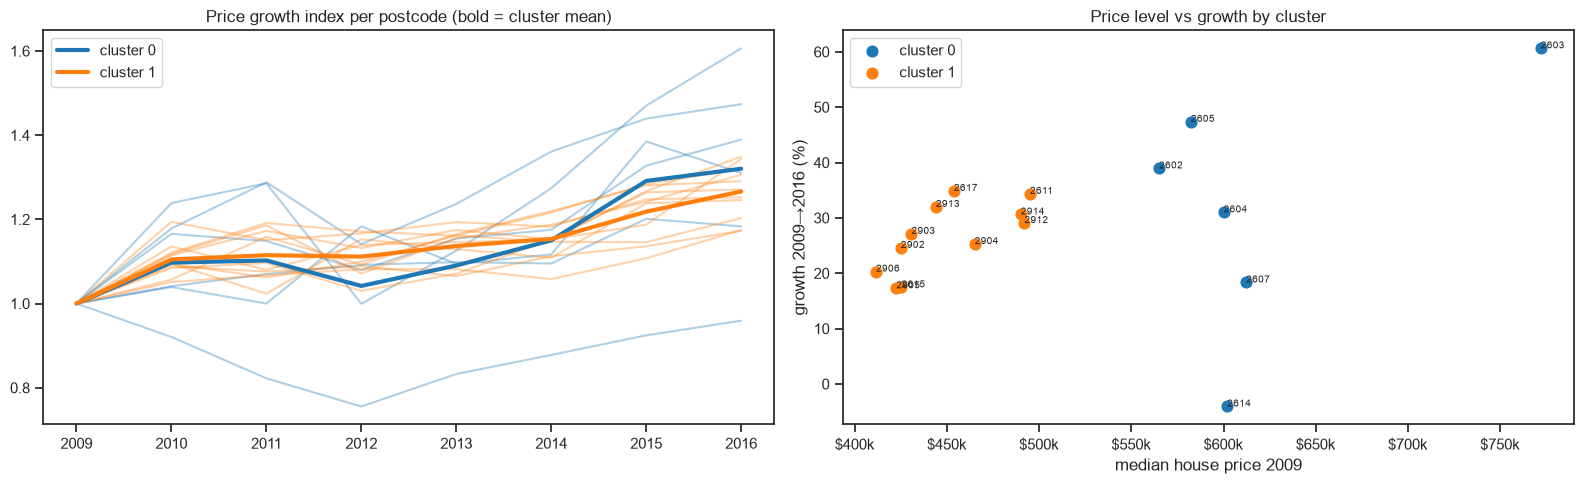

,n_postcodes,median_start,median_growth_pct
cluster,,,
0,6,601000.0,35.0
1,11,444000.0,27.1


In [26]:
ph = tx[(tx["propertyType"] == "house") & (tx["datesold"] < SPLIT_DATE)]
pv = ph.groupby(["postcode", "year"])["price"].agg(["median", "size"])
med, cnt = pv["median"].unstack(), pv["size"].unstack()
years = [yr for yr in med.columns if START_DATE.year < yr < SPLIT_DATE.year]   # complete training years
eligible = (cnt[years] >= 10).all(axis=1)
traj = med.loc[eligible, years]
growth = traj.div(traj.iloc[:, 0], axis=0)
X_pc = np.column_stack([growth.values, StandardScaler().fit_transform(np.log(traj.iloc[:, [0]]))])
print(f"{eligible.sum()} postcodes have ≥10 house sales in every training year {years[0]}–{years[-1]}")

sils = {k: silhouette_score(X_pc, KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_pc))
        for k in range(2, min(7, len(X_pc)))}
K_OVERRIDE = None
PC_K = K_OVERRIDE or max(sils, key=sils.get)
pc_km = KMeans(PC_K, n_init=20, random_state=RANDOM_STATE).fit(X_pc)
pc_cluster = pd.Series(pc_km.labels_, index=traj.index, name="cluster")
print("Silhouette by k:", {k: round(v, 3) for k, v in sils.items()}, "→ k =", PC_K)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors = plt.cm.tab10.colors
for pcode, row in growth.iterrows():
    axes[0].plot(years, row.values, color=colors[pc_cluster[pcode]], alpha=.35)
for c in range(PC_K):
    axes[0].plot(years, growth[pc_cluster == c].mean().values, color=colors[c], lw=3, label=f"cluster {c}")
axes[0].set_title("Price growth index per postcode (bold = cluster mean)")
axes[0].legend()
summary = pd.DataFrame({"cluster": pc_cluster, "first_year_median": traj.iloc[:, 0],
                        "last_year_median": traj.iloc[:, -1], "growth_%": (growth.iloc[:, -1] - 1) * 100})
for c in range(PC_K):
    s = summary[summary["cluster"] == c]
    axes[1].scatter(s["first_year_median"], s["growth_%"], color=colors[c], s=60, label=f"cluster {c}")
    for pcode, rr in s.iterrows():
        axes[1].annotate(pcode, (rr["first_year_median"], rr["growth_%"]), fontsize=7)
axes[1].xaxis.set_major_formatter(dollars)
axes[1].set_xlabel(f"median house price {years[0]}")
axes[1].set_ylabel(f"growth {years[0]}→{years[-1]} (%)")
axes[1].set_title("Price level vs growth by cluster")
axes[1].legend()
plt.tight_layout()
plt.show()
summary.groupby("cluster").agg(n_postcodes=("growth_%", "size"), median_start=("first_year_median", "median"),
                               median_growth_pct=("growth_%", "median")).round(1)

> ✍️ **Your observations (clusters):** describe each cluster (e.g. "expensive inner suburbs, slow growth" vs "affordable outer suburbs, fast growth").

## 11. Feature engineering (supervised framing)
**Target.** Tree-based models can't extrapolate. The test period has higher prices than anything seen in training, so predicting the raw price level would fail. Instead the model predicts the **relative deviation from the trailing 13-week mean**:

$$ y^{rel}_t = \frac{P_t}{\bar P_{t-13..t-1}} - 1 \qquad\Rightarrow\qquad \hat P_t = \bar P_{t-13..t-1}\,(1 + \hat y^{rel}_t) $$

The ADF test in 8.3 shows this target is stationary.

**Features** (all known at the end of week *t−1*):
| Group | Features |
|---|---|
| Lags | price lags 1, 2, 3, 4, 8, 13, 26, 52 weeks, each relative to the 13-week base |
| Rolling | 4-vs-13-week momentum, 13-week volatility, 52-week trend ratio |
| Volume | sales count last week, 4-week average |
| Related series | last week's median **unit** price (relative), last week's median price in each **postcode cluster** (relative) |
| Calendar | week of year (sin/cos), month, quarter, holiday-period flag |

In [27]:
p = weekly["price_clean"]
base = p.shift(1).rolling(13).mean()
F = pd.DataFrame(index=weekly.index)
F[TARGET] = p / base - 1
for k in [1, 2, 3, 4, 8, 13, 26, 52]:
    F[f"lag{k}_rel"] = p.shift(k) / base - 1
F["momentum_4_13"] = p.shift(1).rolling(4).mean() / base - 1
F["volatility_13"] = p.shift(1).rolling(13).std() / base
F["trend_13_52"] = base / p.shift(1).rolling(52).mean() - 1
F["n_sales_lag1"] = weekly["n_sales"].shift(1)
F["n_sales_roll4"] = weekly["n_sales"].shift(1).rolling(4).mean()

units = tx[tx["propertyType"] == "unit"].set_index("datesold")["price"].resample("W-SUN").median().reindex(weekly.index).ffill()
F["unit_rel_lag1"] = units.shift(1) / units.shift(1).rolling(13).mean() - 1

tx_h = tx[tx["propertyType"] == "house"].assign(cluster=lambda d: d["postcode"].map(pc_cluster))
for c in range(PC_K):
    cp = tx_h[tx_h["cluster"] == c].set_index("datesold")["price"].resample("W-SUN").median().reindex(weekly.index).ffill()
    F[f"cluster{c}_rel_lag1"] = cp.shift(1) / base - 1

wk = weekly.index.isocalendar().week.astype(int).values
F["week_sin"], F["week_cos"] = np.sin(2 * np.pi * wk / 52), np.cos(2 * np.pi * wk / 52)
F["month"], F["quarter"] = weekly.index.month, weekly.index.quarter
F["holiday_period"] = np.isin(wk, [51, 52, 53, 1, 2]).astype(int)

F["_base"], F["_actual"], F["_observed"] = base, weekly["median_price"], weekly["observed"]   # helpers, not features
F = F.dropna(subset=[c for c in F.columns if not c.startswith("_") and c != TARGET] + [TARGET])
train_F, test_F = F[F.index < SPLIT_DATE], F[F.index >= SPLIT_DATE]
FEATURES = [c for c in F.columns if not c.startswith("_") and c != TARGET]
print(f"{len(FEATURES)} features | train {len(train_F)} weeks | test {len(test_F)} weeks")
F[FEATURES + [TARGET]].describe().T.round(3)

21 features | train 402 weeks | test 114 weeks


,count,mean,std,min,25%,50%,75%,max
lag1_rel,516.0,0.005,0.054,-0.138,-0.033,0.004,0.040,0.141
lag2_rel,516.0,0.004,0.053,-0.135,-0.031,0.002,0.037,0.142
lag3_rel,516.0,0.003,0.052,-0.129,-0.031,-0.001,0.036,0.139
lag4_rel,516.0,0.002,0.052,-0.134,-0.033,0.000,0.035,0.135
lag8_rel,516.0,-0.001,0.050,-0.150,-0.034,-0.001,0.032,0.134
lag13_rel,516.0,-0.005,0.053,-0.170,-0.041,-0.006,0.032,0.141
lag26_rel,516.0,-0.014,0.058,-0.162,-0.053,-0.018,0.024,0.169
lag52_rel,516.0,-0.034,0.065,-0.194,-0.077,-0.039,0.006,0.207
momentum_4_13,516.0,0.004,0.026,-0.068,-0.015,0.005,0.021,0.093
volatility_13,516.0,0.052,0.012,0.024,0.044,0.052,0.060,0.090


## 12. Feature selection (training period only)
Same approach as the tabular notebook:
1. **Redundancy**: for pairs with |Pearson r| > 0.95, keep the one with higher mutual information (MI).
2. **Noise floor**: random probe features are added, and anything with MI ≤ the best probe is dropped.

AutoViML then applies its own SULOV and recursive-XGBoost selection.

Redundant: ['quarter']
Below noise floor: ['trend_13_52', 'momentum_4_13', 'week_cos', 'month', 'lag26_rel', 'holiday_period', 'lag3_rel', 'cluster1_rel_lag1', 'quarter', 'n_sales_roll4', 'unit_rel_lag1', 'volatility_13', 'lag8_rel']
Kept 8/21: ['lag1_rel', 'lag2_rel', 'lag4_rel', 'lag13_rel', 'lag52_rel', 'n_sales_lag1', 'cluster0_rel_lag1', 'week_sin']


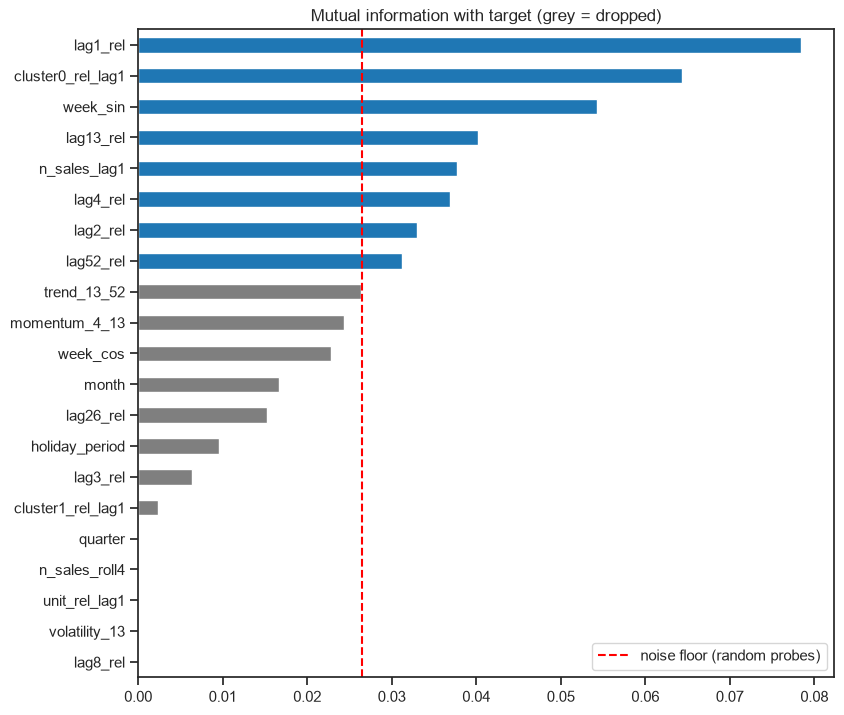

In [28]:
rng = np.random.default_rng(RANDOM_STATE)
X_mi = train_F[FEATURES].copy()
probe_cols = []
for i in range(3):
    X_mi[f"_probe{i}"] = rng.normal(size=len(X_mi))
    probe_cols.append(f"_probe{i}")
mi_all = pd.Series(mutual_info_regression(X_mi, train_F[TARGET], random_state=RANDOM_STATE, n_neighbors=5),
                   index=X_mi.columns).sort_values(ascending=False)
NOISE_FLOOR = mi_all[probe_cols].max()
mi = mi_all.drop(probe_cols)

corr = train_F[FEATURES].corr().abs()
redundant = set()
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        if corr.loc[a, b] > 0.95 and a not in redundant and b not in redundant:
            redundant.add(a if mi[a] < mi[b] else b)
uninformative = mi[mi <= NOISE_FLOOR].index.tolist()
DROP = sorted(redundant | set(uninformative))
selected_features = [f for f in FEATURES if f not in DROP]
# keep at least the 5 most informative features even if MI on ~400 rows is noisy
if len(selected_features) < 5:
    selected_features = mi.head(5).index.tolist()
print("Redundant:", sorted(redundant))
print("Below noise floor:", uninformative)
print(f"Kept {len(selected_features)}/{len(FEATURES)}:", selected_features)

ax = mi.plot.barh(figsize=(8, 8), color=["tab:gray" if f not in selected_features else "tab:blue" for f in mi.index])
ax.invert_yaxis()
ax.axvline(NOISE_FLOOR, color="red", ls="--", label="noise floor (random probes)")
ax.legend()
ax.set_title("Mutual information with target (grey = dropped)")
plt.show()

## 13. Modeling
### 13.1 Naive forecasting baselines
For weekly prices, simple baselines are hard to beat, so they set the bar:
* **Naive**: next week = last week
* **MA-4 / MA-13**: mean of the last 4 or 13 weeks (MA-13 is exactly $\hat y^{rel}=0$)
* **Seasonal naive**: same week last year, scaled by the trend

Every model is scored on **observed** test weeks only. Imputed weeks are excluded, because their "truth" is itself an estimate.

In [29]:
ev = test_F[test_F["_observed"]]
actual = ev["_actual"]


def score(name, pred):
    pred = pd.Series(pred, index=ev.index)
    return {"model": name, "MAE ($)": mean_absolute_error(actual, pred),
            "RMSE ($)": np.sqrt(mean_squared_error(actual, pred)),
            "MAPE (%)": (np.abs(actual - pred) / actual).mean() * 100}


results, preds = [], {}
p_all = weekly["price_clean"]
preds["Naive (last week)"] = p_all.shift(1).loc[ev.index]
preds["MA-4"] = p_all.shift(1).rolling(4).mean().loc[ev.index]
preds["MA-13"] = ev["_base"]
preds["Seasonal naive (52w, trend-adjusted)"] = (p_all.shift(52) * (p_all.shift(1).rolling(13).mean() / p_all.shift(53).rolling(13).mean())).loc[ev.index]
for k, v in preds.items():
    results.append(score(f"Baseline: {k}", v))
pd.DataFrame(results).set_index("model").round(2)

,MAE ($),RMSE ($),MAPE (%)
model,,,
Baseline: Naive (last week),33016.35,42212.53,5.01
Baseline: MA-4,29560.22,37863.52,4.48
Baseline: MA-13,28873.42,35652.75,4.36
"Baseline: Seasonal naive (52w, trend-adjusted)",35137.38,44676.23,5.32


### 13.2 AutoViML (regression)
Same four model families as the tabular notebook (`Boosting_Flag` = `None` linear, `False` random forest, `True` XGBoost, `"CatBoost"`), plus the extra ensemble members each run trains. AutoViML predicts $\hat y^{rel}$, which is converted back to dollars with $\hat P_t = \bar P_{t-13..t-1}(1+\hat y^{rel}_t)$.

**Caveat:** AutoViML's internal validation uses its own (non-chronological) folds. That is why the **honest** evaluation here is the untouched, chronologically later test period.

Imported Auto_ViML version: 0.2.02. Call using:
             m, feats, trainm, testm = Auto_ViML(train, target, test,
                            sample_submission='',
                            scoring_parameter='', KMeans_Featurizer=False,
                            hyper_param='RS',feature_reduction=True,
                             Boosting_Flag='CatBoost', Binning_Flag=False,
                            Add_Poly=0, Stacking_Flag=False,Imbalanced_Flag=False,
                            GPU_flag=False, verbose=1)
            

Imported Auto_NLP version: 0.1.01.. Call using:
     train_nlp, test_nlp, nlp_pipeline, predictions = Auto_NLP(
                nlp_column, train, test, target, score_type='balanced_accuracy',
                modeltype='Classification',top_num_features=200, verbose=0,
                build_model=True)

============================== AutoViML: Linear (Boosting_Flag=None) ==============================
##############  D A T A   S E T  A N A L Y S I S  #######

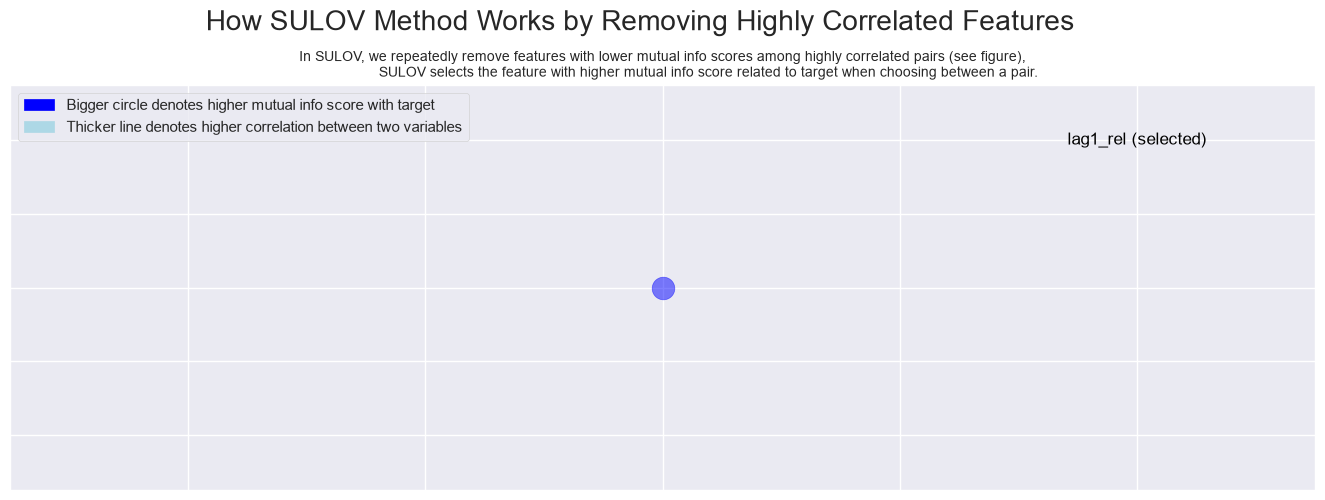

Splitting selected features into float and categorical (integer) variables:
    (8) float variables ...
    (0) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 8 
    Finding Important Features using Boosted Trees algorithm...
        using 8 variables...
        using 6 variables...
        using 4 variables...


        using 2 variables...
Found 8 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  361 , CV rows =  41
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling of train and validation data
#################################################################################
######## Linear    M O D E L   T R A I N I N G   ##########
#################################################################################
Rows in Train data set = 361
  Features in Train data set = 8
    Rows in held-out data set = 41
     Handling Imbalanced flag...
Finding Best Model and Hyper Parameters for Linear model...
    CPU Count = 14 in this device
Using Linear Model, Estimated Training time = 0.003 mins


    Actual training time (in seconds): 3
###########  Single_Label  M O D E L   R E S U L T S #################
5-fold Cross Validation rmse Score = 0.0568
    Best Parameters for Model = {'C': 23.504378152453466, 'epsilon': 0.0065530026811640996}
########################################################
Linear Model Prediction Results on Held Out CV Data Set:
Regression Plots completed in 0.008 seconds
    MAE = 0.0584
    MAPE = 205% (MAPE will be very high when zeros in actuals)
    RMSE = 0.0722
    Normalized MAE (as % std dev of Actuals) = 146%
    Normalized RMSE (% of Std Dev of Actuals) = 104%
################# E N S E M B L E  M O D E L  ##################


Time taken = 0 seconds
Based on trying multiple models, Best type of algorithm for this data set is Adaboost
    Displaying results of weighted average ensemble of 5 regressors
#############################################################################
Regression Plots completed in 0.006 seconds
    MAE = 0.0585
    MAPE = 163% (MAPE will be very high when zeros in actuals)
    RMSE = 0.0726
    Normalized MAE (as % std dev of Actuals) = 147%
    Normalized RMSE (% of Std Dev of Actuals) = 105%
After multiple models, Ensemble Model Results:
    RMSE Score = 0.07263
#############################################################################
Single Model is better than Ensembling Models for this data set.
    Time taken for this Target (in seconds) = 4
    Binning_Flag set to False or there are no float vars in data set to be binned
Performing MinMax scaling of train and test data...
###########################################################################
#####   F I N A L I Z I N

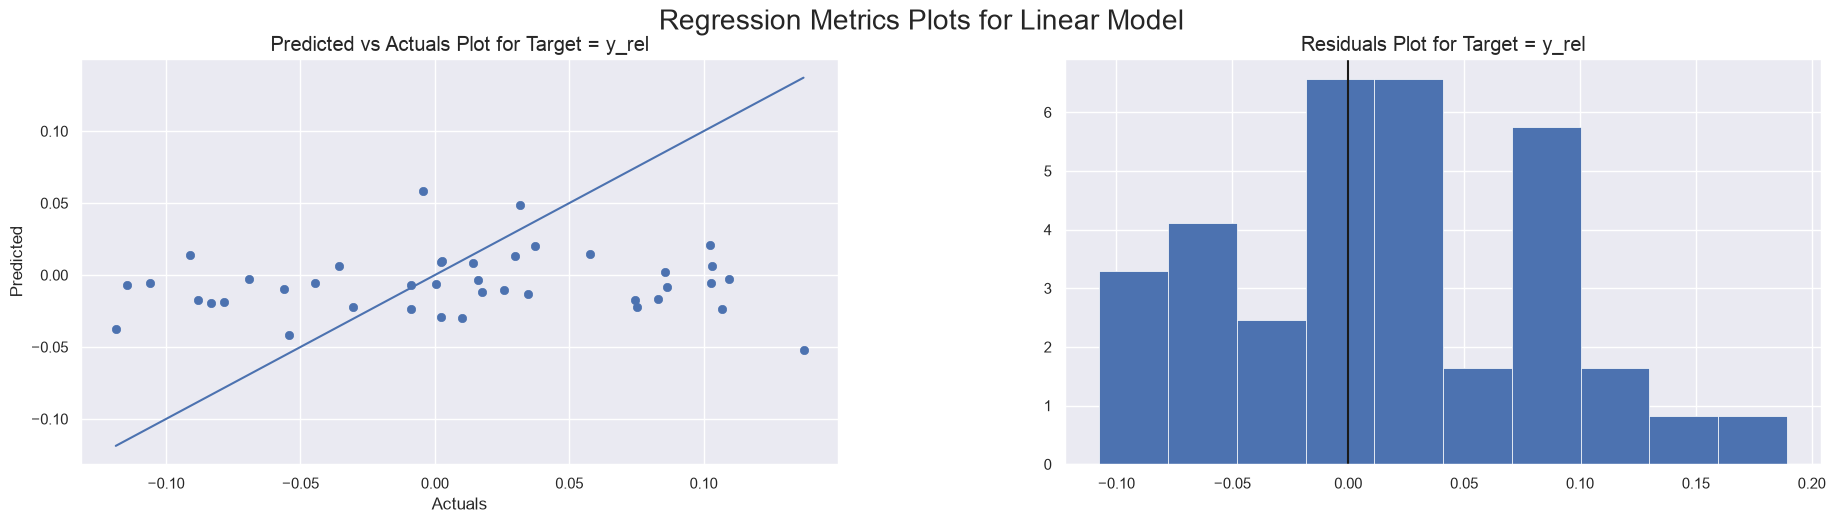

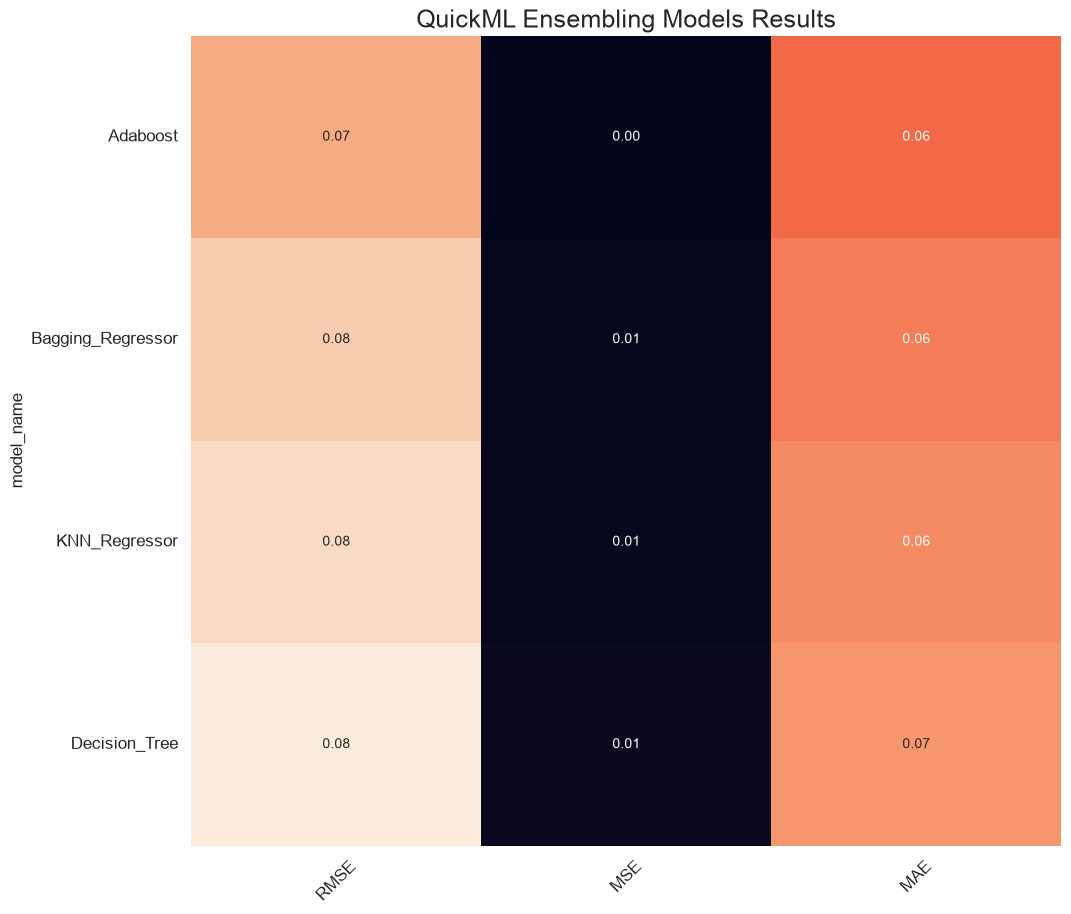

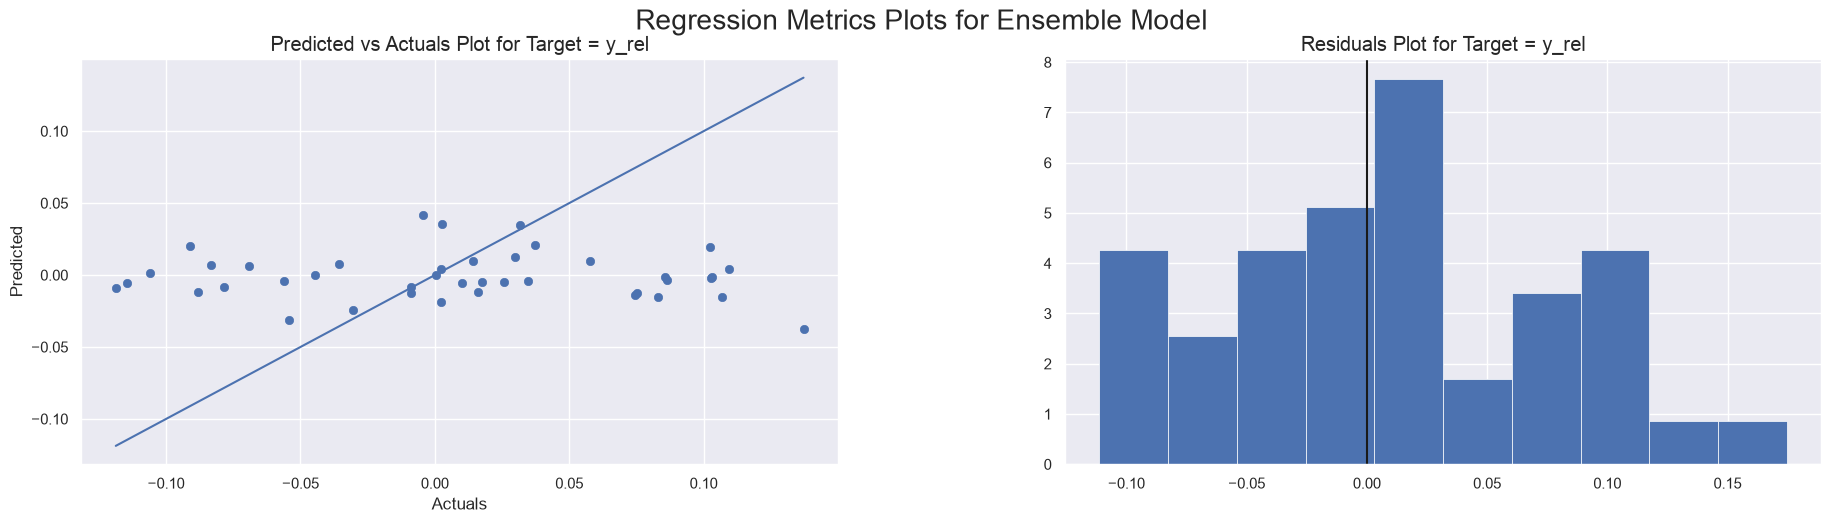

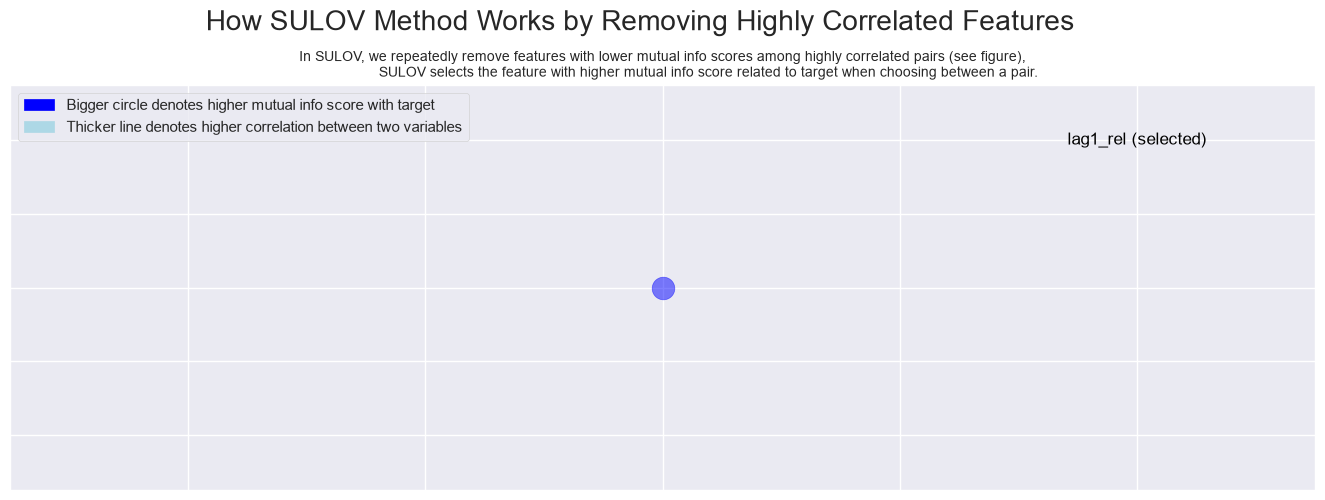

Splitting selected features into float and categorical (integer) variables:
    (8) float variables ...
    (0) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 8 
    Finding Important Features using Boosted Trees algorithm...
        using 8 variables...
        using 6 variables...
        using 4 variables...
        using 2 variables...
Found 8 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  361 , CV rows =  41
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling of train and validation data
#########

    Actual training time (in seconds): 5
###########  Single_Label  M O D E L   R E S U L T S #################
5-fold Cross Validation rmse Score = 0.0577
    Best Parameters for Model = {'max_depth': 5, 'min_samples_leaf': 7, 'n_estimators': 240}
########################################################
Forests Model Prediction Results on Held Out CV Data Set:
Regression Plots completed in 0.007 seconds
    MAE = 0.0484
    MAPE = 138% (MAPE will be very high when zeros in actuals)
    RMSE = 0.0598
    Normalized MAE (as % std dev of Actuals) = 142%
    Normalized RMSE (% of Std Dev of Actuals) = 101%
################# E N S E M B L E  M O D E L  ##################
Time taken = 0 seconds
Based on trying multiple models, Best type of algorithm for this data set is KNN_Regressor
    Displaying results of weighted average ensemble of 5 regressors
#############################################################################
Regression Plots completed in 0.006 seconds
    MAE = 0.0471
   

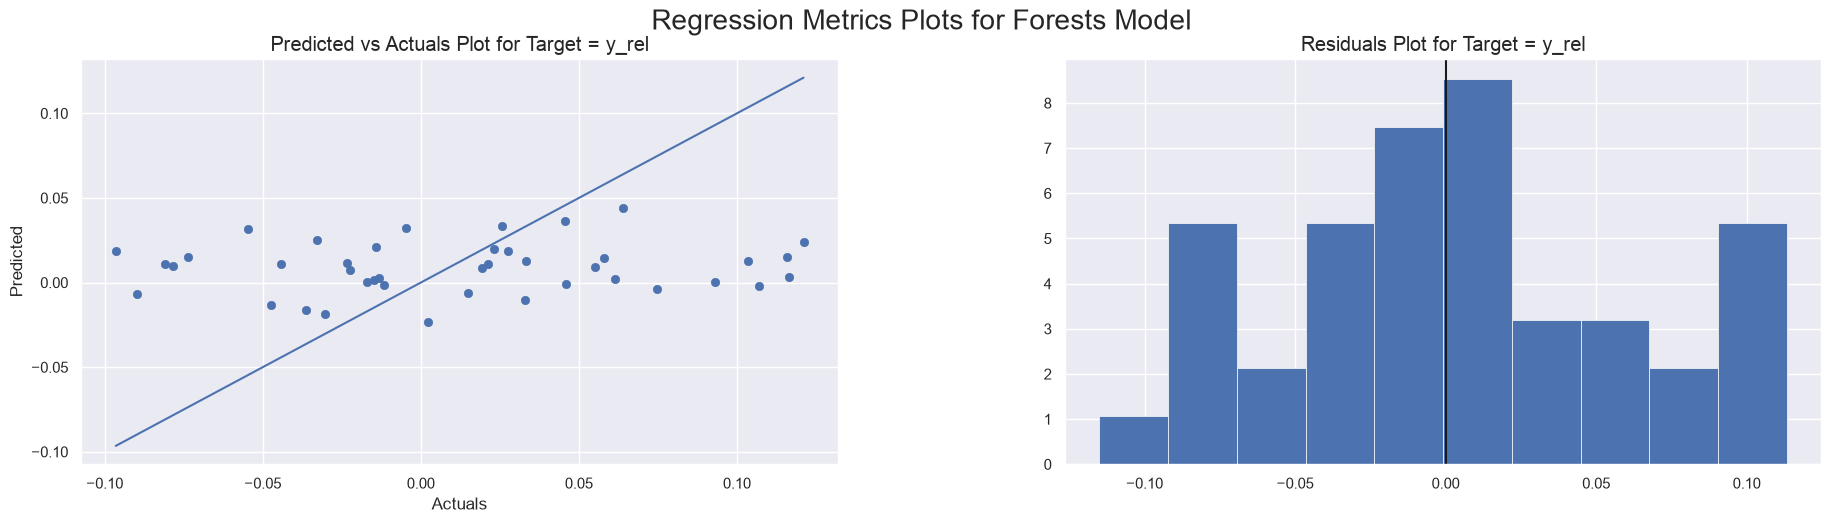

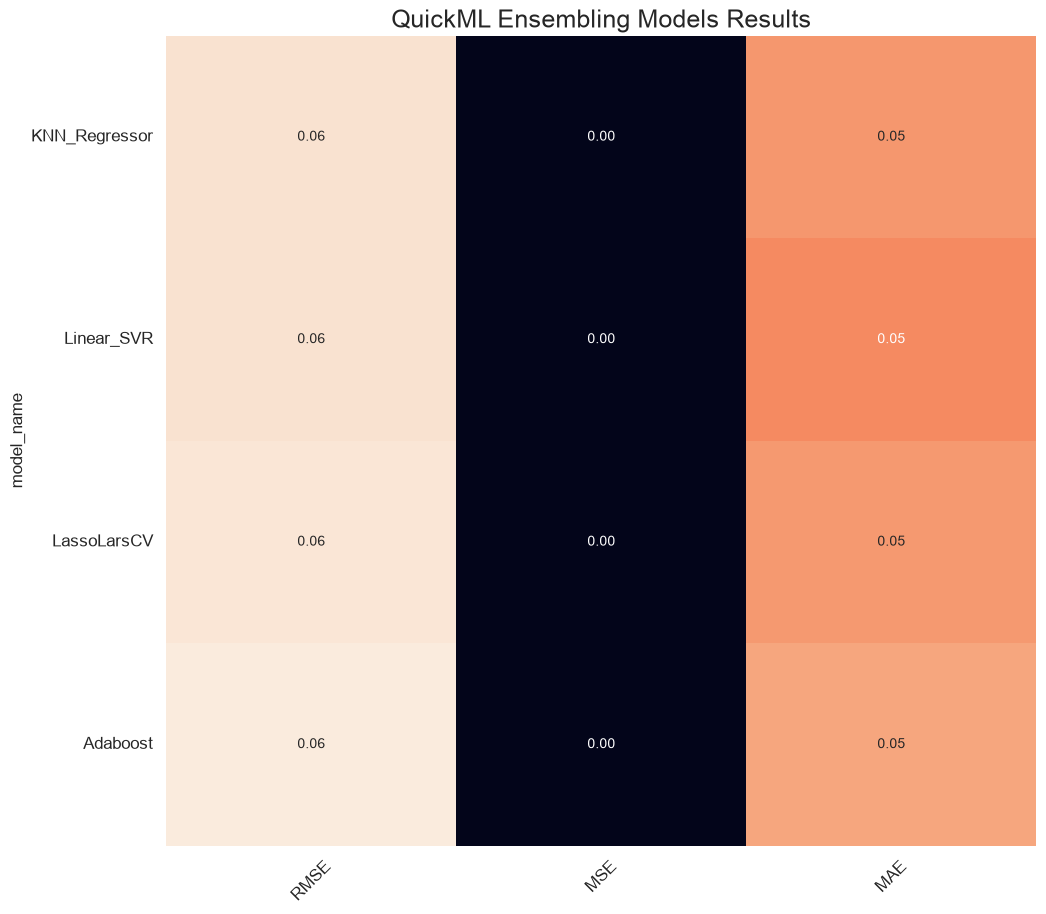

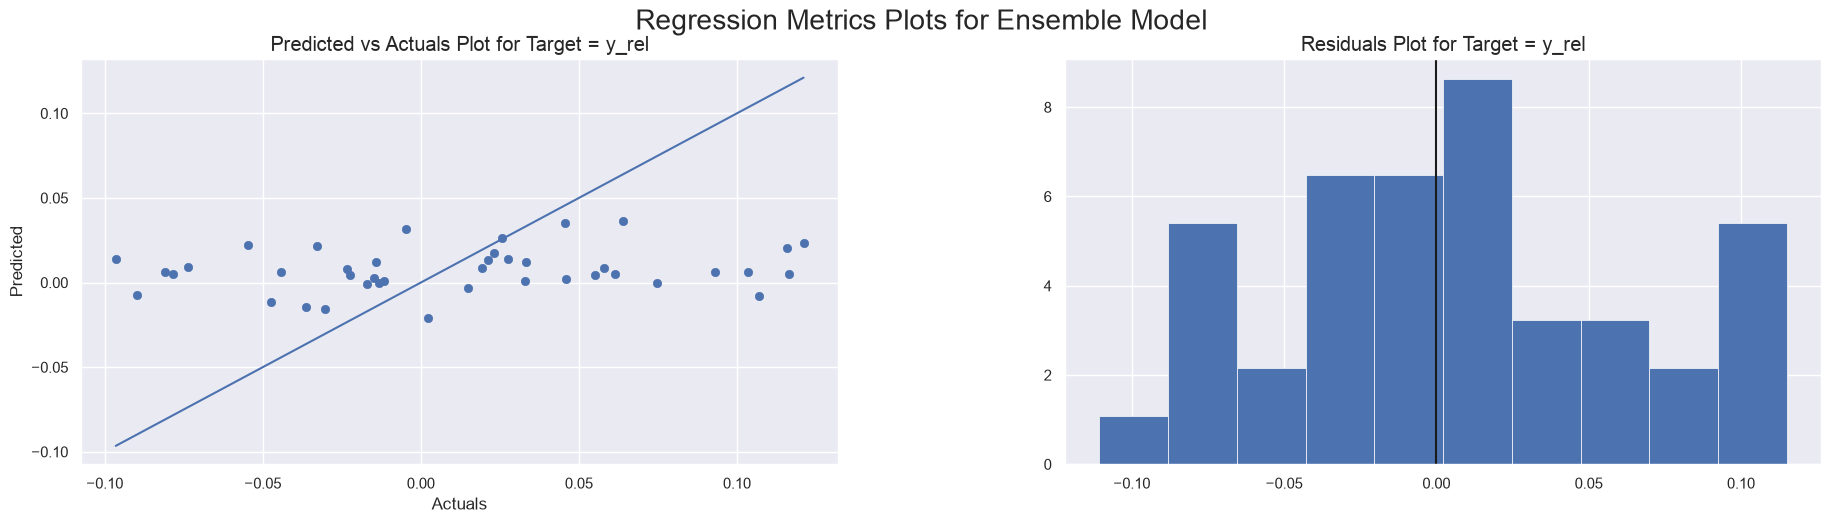

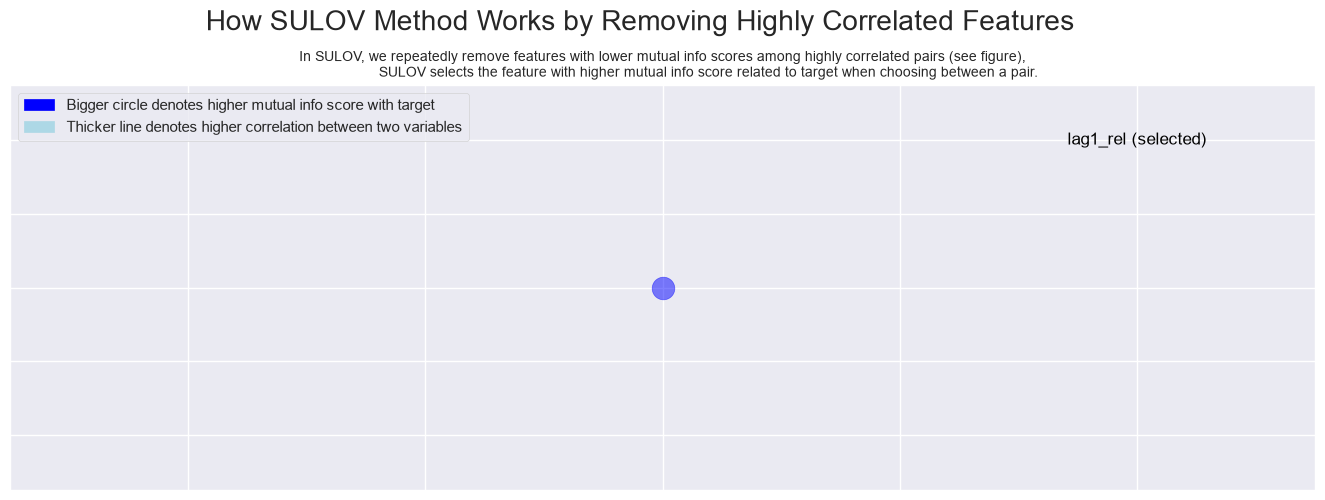

Splitting selected features into float and categorical (integer) variables:
    (8) float variables ...
    (0) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 8 
    Finding Important Features using Boosted Trees algorithm...
        using 8 variables...
        using 6 variables...
        using 4 variables...
        using 2 variables...
Found 8 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  361 , CV rows =  41
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling of train and validation data
#########

    Actual training time (in seconds): 0
###########  Single_Label  M O D E L   R E S U L T S #################
5-fold Cross Validation rmse Score = 0.0608
    Best Parameters for Model = {'gamma': 17, 'learning_rate': 0.9906273994707961, 'max_depth': 6, 'n_estimators': 207}
########################################################
XGBoost Model Prediction Results on Held Out CV Data Set:
Regression Plots completed in 0.007 seconds
    MAE = 0.0449
    MAPE = 99% (MAPE will be very high when zeros in actuals)
    RMSE = 0.0572
    Normalized MAE (as % std dev of Actuals) = 124%
    Normalized RMSE (% of Std Dev of Actuals) = 101%
################# E N S E M B L E  M O D E L  ##################
Time taken = 0 seconds
Based on trying multiple models, Best type of algorithm for this data set is LassoLarsCV
    Displaying results of weighted average ensemble of 5 regressors
#############################################################################
Regression Plots completed in 0.006 seco

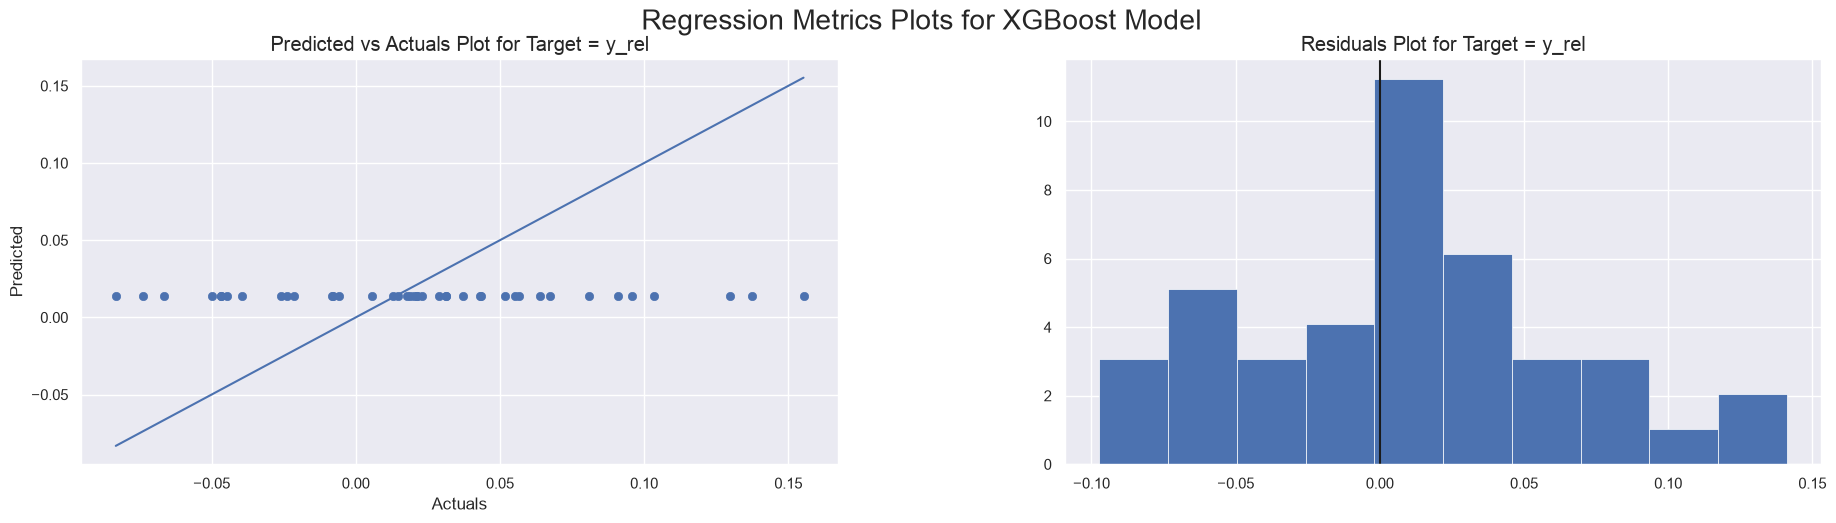

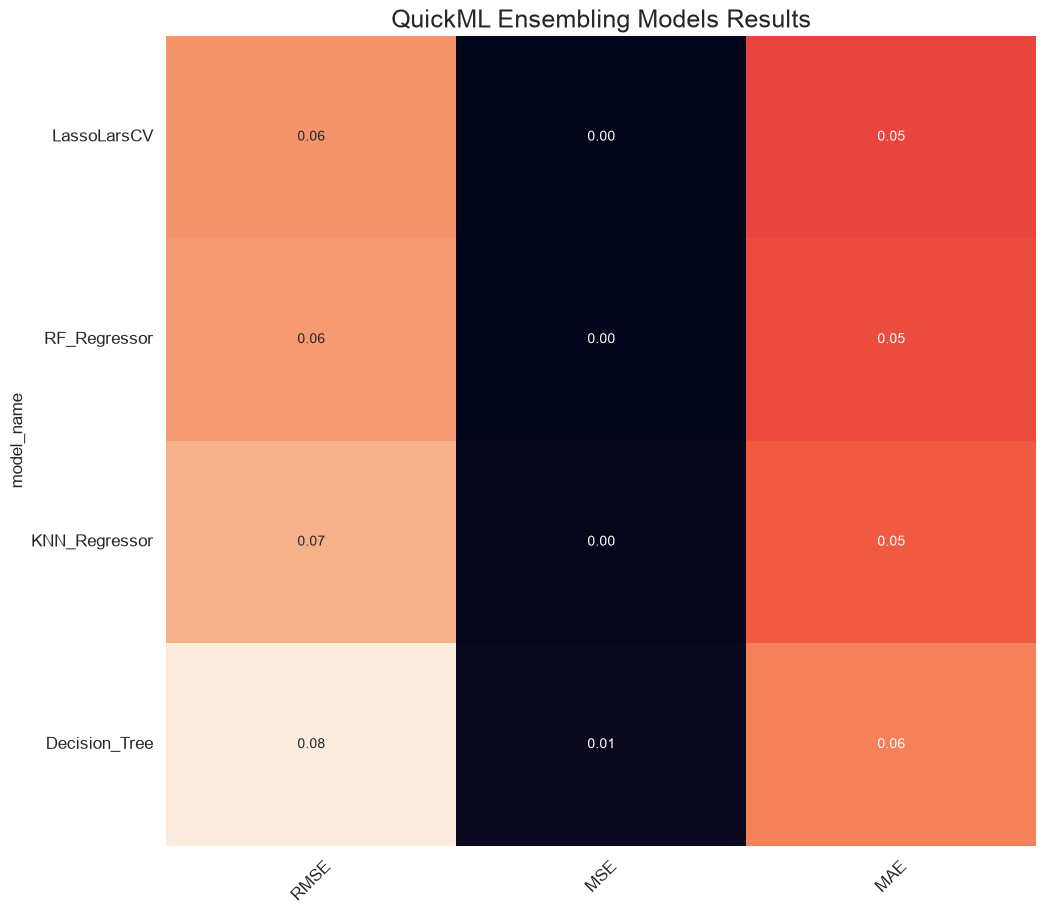

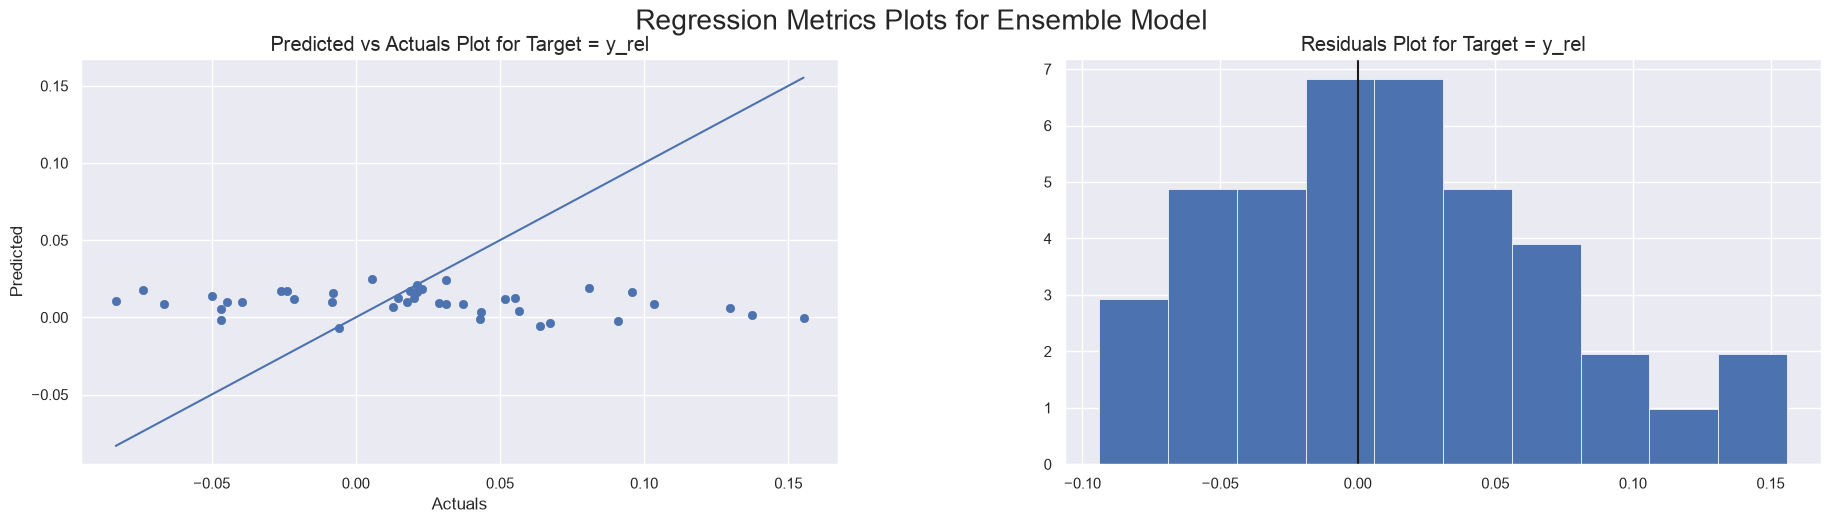

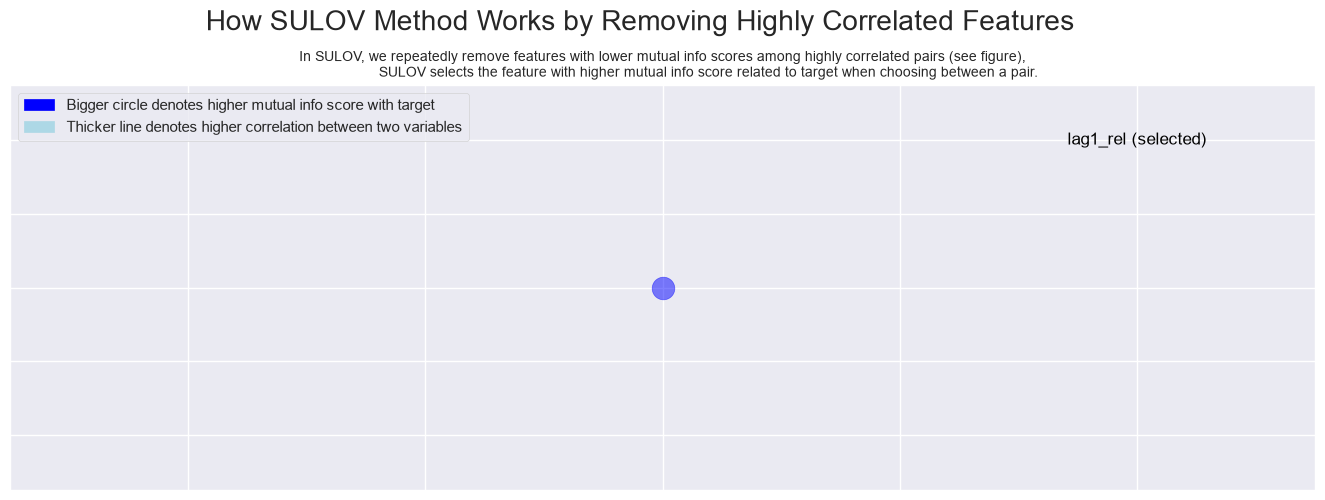

Splitting selected features into float and categorical (integer) variables:
    (8) float variables ...
    (0) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 8 
    Finding Important Features using Boosted Trees algorithm...
        using 8 variables...
        using 6 variables...
        using 4 variables...
        using 2 variables...
Found 8 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  361 , CV rows =  41
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Skipping MinMax scaling since perform_scaling flag is set to Fal

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

Learning rate set to 0.022201
0:	learn: 0.0597772	test: 0.0565571	best: 0.0565571 (0)	total: 68ms	remaining: 3m 23s


500:	learn: 0.0297531	test: 0.0589309	best: 0.0550430 (63)	total: 208ms	remaining: 1.03s
1000:	learn: 0.0152831	test: 0.0612696	best: 0.0550430 (63)	total: 331ms	remaining: 661ms


1500:	learn: 0.0082043	test: 0.0625125	best: 0.0550430 (63)	total: 454ms	remaining: 453ms
2000:	learn: 0.0045312	test: 0.0630396	best: 0.0550430 (63)	total: 577ms	remaining: 288ms
Stopped by overfitting detector  (2000 iterations wait)

bestTest = 0.05504300954
bestIteration = 63

Shrink model to first 64 iterations.
    Actual training time (in seconds): 1
###########  Single_Label  M O D E L   R E S U L T S #################
5-fold Cross Validation RMSE Score = 0.0550
    CatBoost Best Parameters for Model: Iterations = 63, learning_rate = 0.02
########################################################
CatBoost Model Prediction Results on Held Out CV Data Set:
Regression Plots completed in 0.007 seconds
    MAE = 0.0412
    MAPE = 85% (MAPE will be very high when zeros in actuals)
    RMSE = 0.0550
    Normalized MAE (as % std dev of Actuals) = 117%
    Normalized RMSE (% of Std Dev of Actuals) = 98%
################# E N S E M B L E  M O D E L  ##################
Time taken = 0 second

62:	learn: 0.0531948	total: 20.2ms	remaining: 0us
     Actual Training time taken in seconds = 0
Training of models completed. Now starting predictions on test data...
    Calculating weighted average ensemble of 5 regressors
Completed Ensemble predictions on held out data
    Plotting Feature Importances to explain the output of model
############### P R E D I C T I O N  O N  T E S T   C O M P L E T E D  #################
    Time taken thus far (in seconds) = 1
Writing Output files to disk...
    Saving predictions to ./y_rel/y_rel_Regression_test_modified.csv
    Saving predictions to ./y_rel/y_rel_Regression_submission.csv
    Saving predictions to ./y_rel/y_rel_Regression_train_modified.csv
###############  C O M P L E T E D  ################
Time Taken in mins = 0.0 for the Entire Process


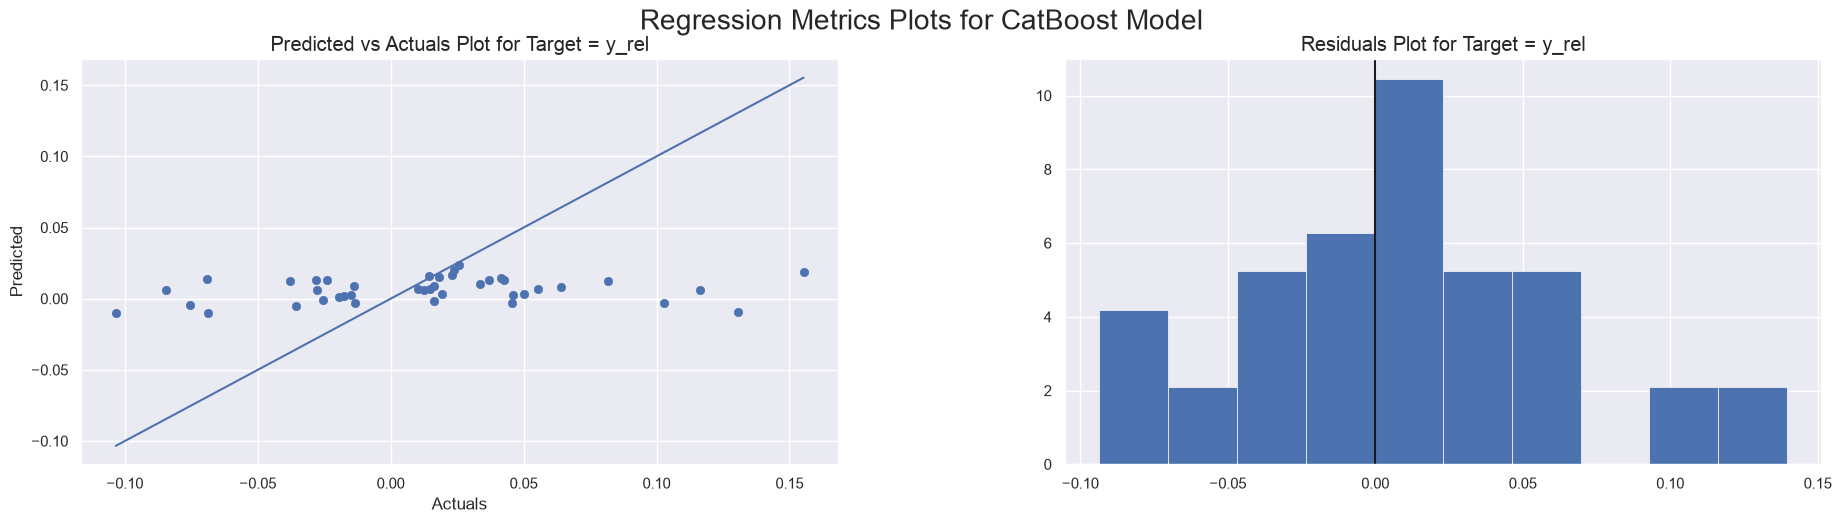

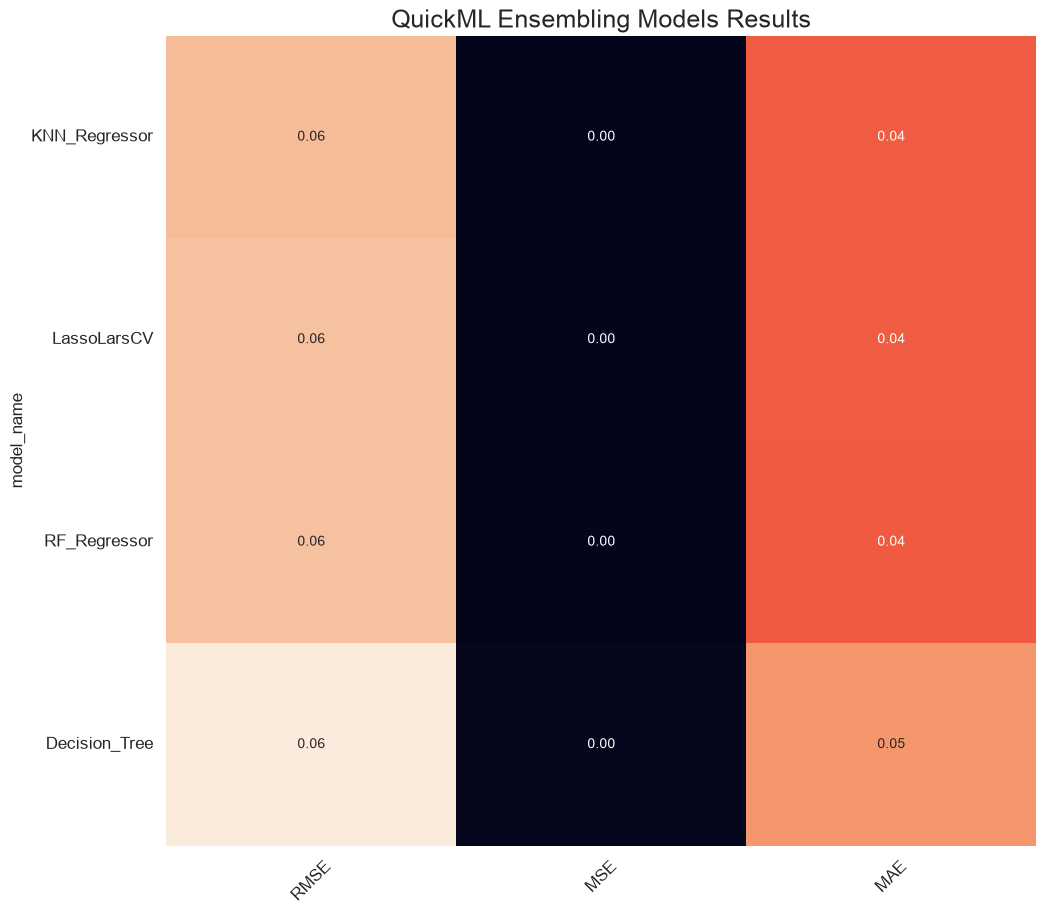

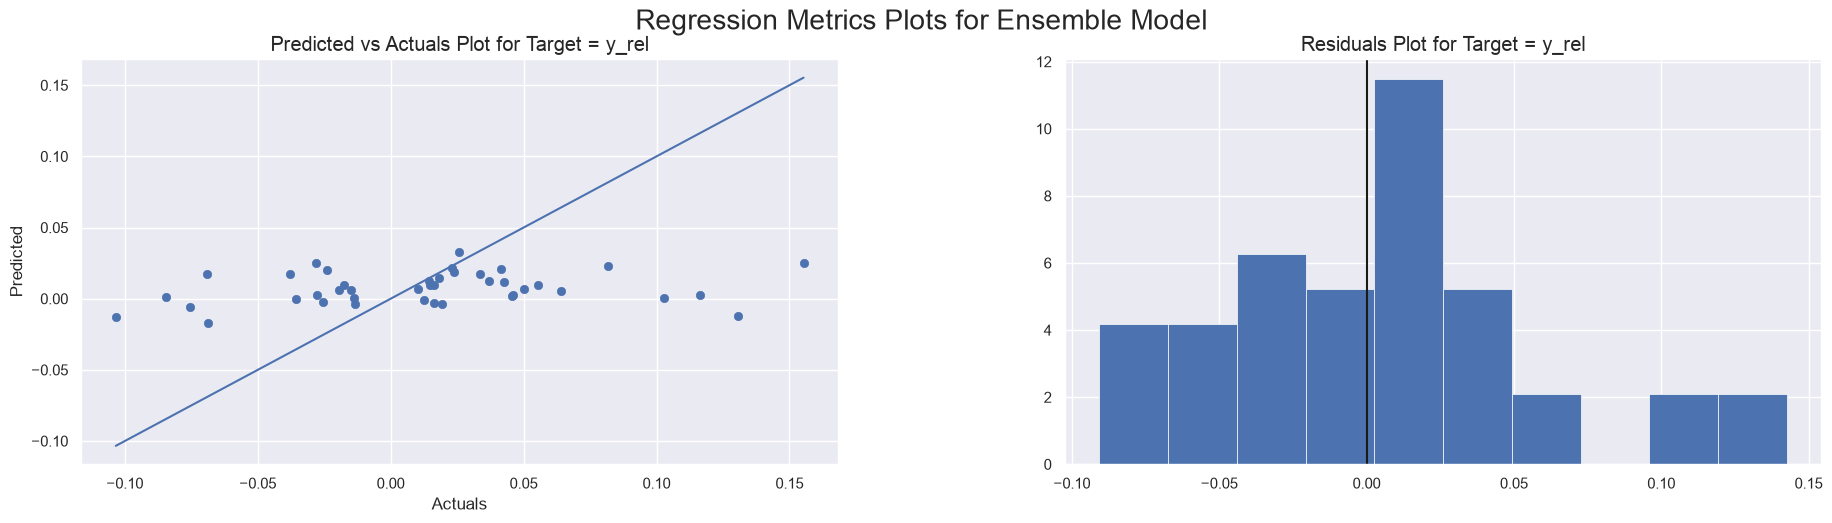

In [30]:
from autoviml.Auto_ViML import Auto_ViML

AVML_CONFIGS = {"Linear": None, "RandomForest": False, "XGBoost": True, "CatBoost": "CatBoost"}
avml_train = train_F[selected_features + [TARGET]].reset_index(drop=True)
avml_test = test_F[selected_features].reset_index(drop=True)
avml_runs, seen = {}, set()
ev_mask = test_F["_observed"].values

for name, flag in AVML_CONFIGS.items():
    print(f"\n{'=' * 30} AutoViML: {name} (Boosting_Flag={flag!r}) {'=' * 30}")
    model, feats, trainm, testm = Auto_ViML(
        avml_train.copy(), TARGET, avml_test.copy(), sample_submission="",
        hyper_param="RS", feature_reduction=True, scoring_parameter="",
        Boosting_Flag=flag, KMeans_Featurizer=False, Binning_Flag=False, Add_Poly=0,
        Stacking_Flag=False, Imbalanced_Flag=False, verbose=0)
    avml_runs[name] = {"model": model, "features": feats, "testm": testm}
    main_col = f"{TARGET}_predictions"
    for col in testm.columns:
        if not col.endswith("_predictions"):
            continue
        if col != main_col and testm[col].equals(testm[main_col]):
            continue
        sub = col[len(TARGET) + 1:-len("_predictions")]
        label = f"AutoViML {name}" if col == main_col else (
            f"AutoViML {name} → Ensemble" if sub == "Ensembled" else f"AutoViML ensemble member: {sub}")
        if label in seen:
            continue
        seen.add(label)
        price_hat = test_F["_base"].values * (1 + testm[col].values)
        preds[label] = pd.Series(price_hat[ev_mask], index=ev.index)
        results.append(score(label, preds[label]))

## 14. Results

,MAE ($),RMSE ($),MAPE (%)
model,,,
AutoViML Linear → Ensemble,"26,629","34,211",4.06
AutoViML CatBoost → Ensemble,"26,932","33,892",4.10
AutoViML ensemble member: Linear_SVR,"26,987","35,038",4.10
AutoViML RandomForest,"27,123","33,965",4.12
AutoViML RandomForest → Ensemble,"27,162","34,140",4.13
AutoViML ensemble member: RF_Regressor,"27,215","34,618",4.14
AutoViML Linear,"27,280","35,633",4.18
AutoViML XGBoost → Ensemble,"27,301","35,072",4.14
AutoViML ensemble member: Decision_Tree,"27,355","35,185",4.15


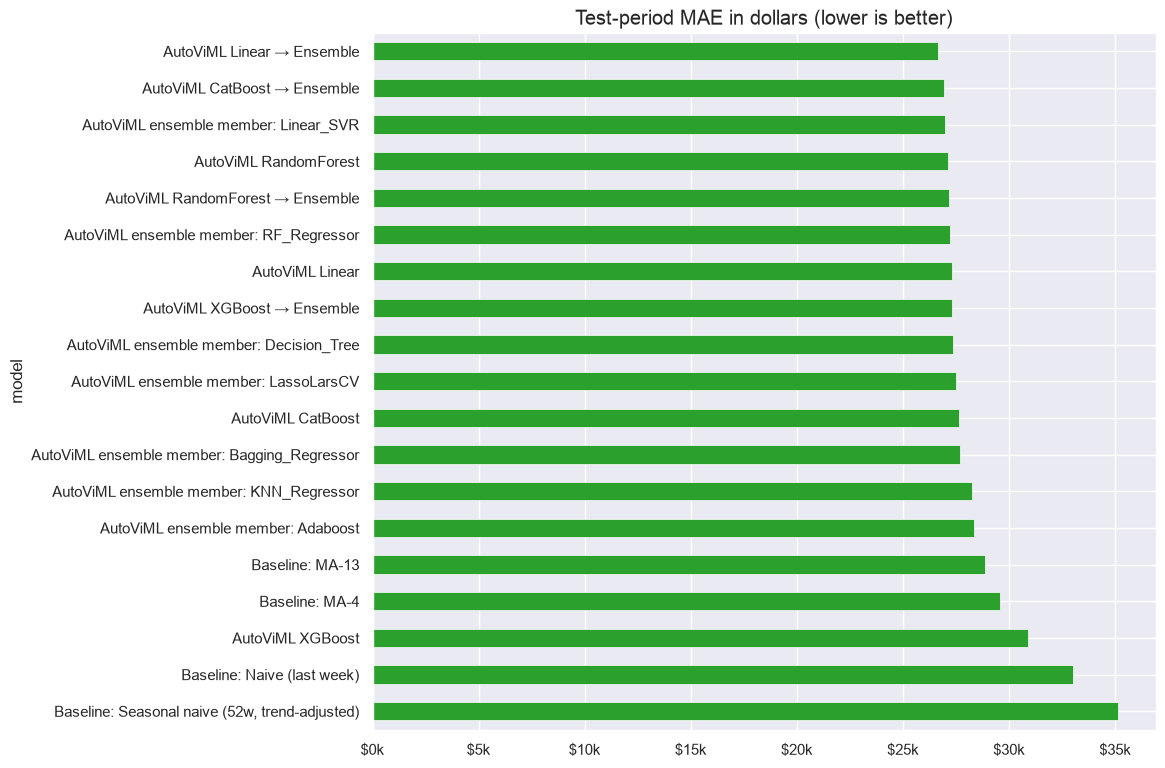

In [31]:
res = pd.DataFrame(results).set_index("model").sort_values("MAE ($)")
display(res.style.format({"MAE ($)": "{:,.0f}", "RMSE ($)": "{:,.0f}", "MAPE (%)": "{:.2f}"})
        .background_gradient(cmap="Greens_r", subset=["MAE ($)", "MAPE (%)"]))
res["MAE ($)"].sort_values(ascending=False).plot.barh(figsize=(9, 0.4 * len(res) + 1), color="tab:green")
plt.title("Test-period MAE in dollars (lower is better)")
plt.gca().xaxis.set_major_formatter(dollars)
plt.show()

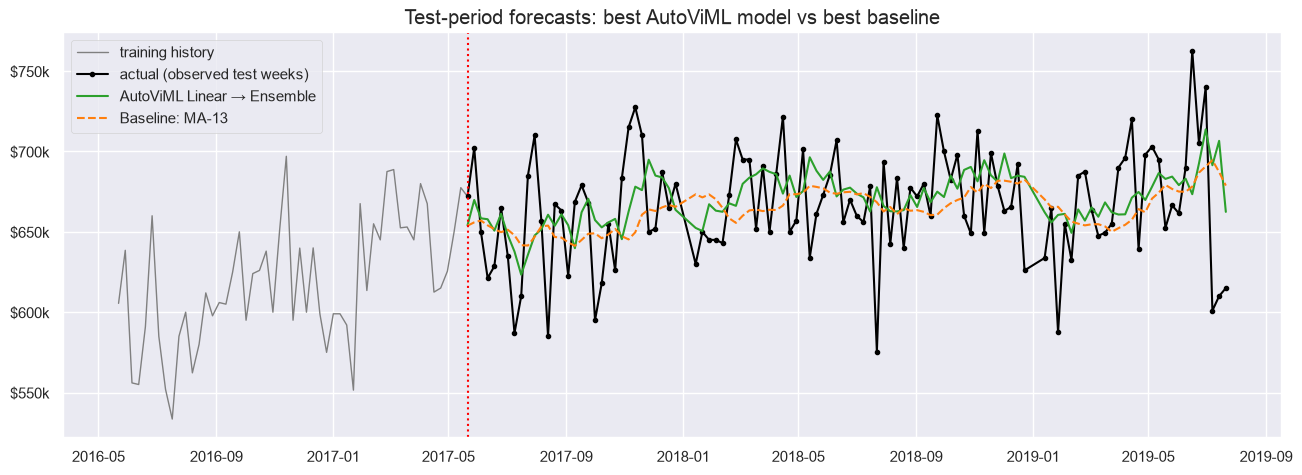

In [32]:
best_avml = res.filter(like="AutoViML", axis=0).index[0]
best_base = res.filter(like="Baseline", axis=0).index[0]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weekly["price_clean"].loc[SPLIT_DATE - pd.Timedelta(weeks=52):SPLIT_DATE], color="grey", lw=1, label="training history")
ax.plot(actual, color="black", lw=1.5, marker=".", label="actual (observed test weeks)")
ax.plot(preds[best_avml], color="tab:green", lw=1.5, label=f"{best_avml}")
ax.plot(preds[best_base.replace("Baseline: ", "")], color="tab:orange", lw=1.5, ls="--", label=best_base)
ax.axvline(SPLIT_DATE, color="red", ls=":")
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Test-period forecasts: best AutoViML model vs best baseline")
ax.legend()
plt.show()

Best main AutoViML model: AutoViML RandomForest


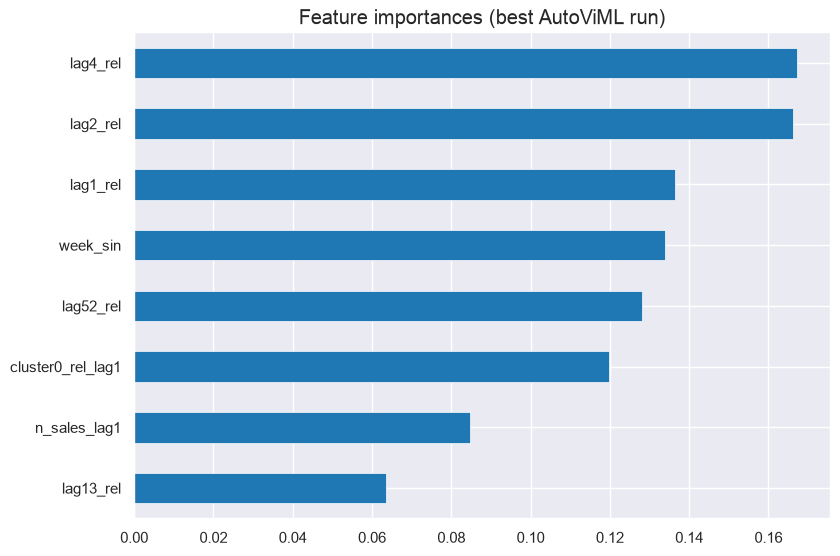

In [33]:
best_main = res[res.index.isin([f"AutoViML {k}" for k in avml_runs])].index[0]   # res is sorted by MAE
best_run = avml_runs[best_main.replace("AutoViML ", "")]
print("Best main AutoViML model:", best_main)
m = best_run["model"]
est = m.steps[-1][1] if hasattr(m, "steps") else m
if hasattr(est, "feature_importances_") and len(est.feature_importances_) == len(best_run["features"]):
    pd.Series(est.feature_importances_, index=best_run["features"]).sort_values().plot.barh(
        figsize=(8, 6), color="tab:blue", title="Feature importances (best AutoViML run)")
    plt.show()
else:
    print("Features kept by AutoViML:", best_run["features"])

## 15. Conclusions
> ✍️ **TODO (you), after running everything:**
> - **Data preparation:** what the raw transactions needed (bedroom imputation, price anomalies, sparse early years, missing weeks) and why the weekly series was built the way it was.
> - **Time-series findings:** trend, seasonality, stationarity, postcode clusters.
> - **Models:** did any AutoViML model beat the naive baselines? By how much in dollars? If not, explain why: weekly medians are noisy and close to a random walk around the trend, so this is itself a useful finding.
> - **Limitations and next steps:** monthly frequency, forecasting each postcode cluster separately, walk-forward (rolling-origin) validation, dedicated time-series AutoML (e.g. Auto_TS).